<a href="https://colab.research.google.com/github/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02/blob/main/DBTT_06_danh_gia_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sổ tay 06: Đánh giá Ld, Lq của MLP và Rs đại số trên tập kiểm thử

**Dự án:** Nhận dạng tham số động cơ PMSM: mạng MLP nhận dạng Ld, Lq theo (id, iq); Rs tính đại số từ Ld, Lq đã nhận dạng.

**Nguyên tắc:** sổ tay chạy độc lập; mỗi lần chạy đều thiết lập lại môi trường từ đầu. Mã được viết, kiểm thử bằng dữ liệu mẫu, xuất thành tệp `.py` rồi đẩy lên GitHub theo bốn bước của PRD.

**Cách đánh giá:** MLP dự đoán (Ld, Lq) từ (id, iq); Rs được tính bằng bộ ước lượng đại số có lọc ba lớp (phương pháp của sổ tay 08 bản v6) từ chính Ld, Lq đó. Đường đối chứng tính Rs bằng cùng bộ ước lượng và cùng cấu hình nhưng dùng nhãn Ld, Lq, nên sai khác giữa hai đường là do Ld, Lq của MLP.

### Sơ đồ khối của sổ tay (BPMN 2.0, ISO/IEC 19510)



*Hình: Sơ đồ khối quá trình của sổ tay 06*

## Cell 1 – Thiết lập môi trường

In [1]:
# Cell 1 - Thiết lập môi trường từ đầu: gắn Drive, nhận mã truy cập, sao chép kho mã
import os  # Thao tác đường dẫn và tệp
import sys  # Điều chỉnh đường dẫn nạp mô-đun
import subprocess  # Chạy lệnh git và pip
from google.colab import drive, userdata  # Gắn Drive và đọc bí mật của Colab
drive.mount('/content/drive')  # Gắn Google Drive vào phiên Colab
GITHUB_USER = 'maivu18082005-hub'  # Tài khoản GitHub chứa kho mã
REPO_NAME = 'Parameter_Identification_of_PMSM_using_PINN_02'  # Tên kho mã
REPO_DIR = f'/content/{REPO_NAME}'  # Thư mục kho trên máy Colab
TOKEN = userdata.get('GITHUB_TOKEN')  # Mã truy cập lấy từ Colab Secrets
REMOTE = f'https://{TOKEN}@github.com/{GITHUB_USER}/{REPO_NAME}.git'  # Địa chỉ kho kèm mã truy cập


def run(cmd, check=True):  # Hàm chạy lệnh và che mã truy cập trong đầu ra
    r = subprocess.run(cmd, capture_output=True, text=True)  # Chạy lệnh, thu đầu ra
    out = (r.stdout + r.stderr).replace(TOKEN, '***')  # Thay mã truy cập bằng dấu sao
    if check and r.returncode != 0:  # Nếu lệnh lỗi và yêu cầu kiểm tra
        raise RuntimeError(out)  # Báo lỗi kèm đầu ra đã che
    return out  # Trả về đầu ra


def push_files(paths, message):  # Hàm đẩy tệp lên GitHub
    run(['git', '-C', REPO_DIR, 'config', 'user.name', GITHUB_USER])  # Đặt tên người commit
    run(['git', '-C', REPO_DIR, 'config', 'user.email', f'{GITHUB_USER}@users.noreply.github.com'])  # Đặt email người commit
    run(['git', '-C', REPO_DIR, 'add'] + paths)  # Thêm các tệp vào vùng chờ
    if not run(['git', '-C', REPO_DIR, 'status', '--porcelain']).strip():  # Nếu không có thay đổi
        print('Không có thay đổi để đẩy')  # Thông báo
        return  # Kết thúc hàm
    run(['git', '-C', REPO_DIR, 'commit', '-m', message])  # Tạo commit
    run(['git', '-C', REPO_DIR, 'branch', '-M', 'main'])  # Đảm bảo nhánh là main
    run(['git', '-C', REPO_DIR, 'pull', '--rebase', REMOTE, 'main'], check=False)  # Đồng bộ trước khi đẩy
    print(run(['git', '-C', REPO_DIR, 'push', REMOTE, 'HEAD:main']))  # Đẩy lên GitHub


if os.path.isdir(os.path.join(REPO_DIR, '.git')):  # Nếu kho đã có trên máy
    run(['git', '-C', REPO_DIR, 'pull', REMOTE, 'main'], check=False)  # Cập nhật kho
else:  # Nếu chưa có
    run(['git', 'clone', REMOTE, REPO_DIR])  # Sao chép kho từ GitHub
sys.path.insert(0, REPO_DIR)  # Cho phép nạp mô-đun từ kho
TESTS_OK = False  # Cờ cho phép đẩy mã, chỉ bật sau khi kiểm thử đạt
print('Kho mã sẵn sàng tại', REPO_DIR)  # Thông báo hoàn tất

req = os.path.join(REPO_DIR, 'requirements.txt')  # Tệp yêu cầu thư viện
if os.path.exists(req):  # Nếu tệp tồn tại
    run([sys.executable, '-m', 'pip', 'install', '-q', '-r', req])  # Cài thư viện
import torch  # Thư viện học sâu
from src.utils.common import load_config, set_seed, get_paths  # Tiện ích dùng chung
cfg = load_config(os.path.join(REPO_DIR, 'configs', 'config.yaml'))  # Nạp cấu hình
set_seed(cfg['project']['seed'])  # Cố định hạt giống
PATHS = get_paths(cfg)  # Đường dẫn tuyệt đối trên Drive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # Chọn thiết bị tính toán
print('Thiết bị:', DEVICE, '| Torch:', torch.__version__)  # In thông tin môi trường

Mounted at /content/drive
Kho mã sẵn sàng tại /content/Parameter_Identification_of_PMSM_using_PINN_02
Thiết bị: cpu | Torch: 2.14.1+cpu


## Cell 2 – Kiểm tra điều kiện đầu vào
Cần trọng số `mlp_best.pt` từ sổ tay 05, dữ liệu đã xử lý từ sổ tay 02 và `config.yaml` có khối `rs_estimator` đầy đủ từ sổ tay 01.

In [2]:
# Cell 2 - Kiểm tra điều kiện đầu vào
import json  # Đọc ghi JSON
import importlib  # Nạp lại mô-đun
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
assert os.path.exists(os.path.join(PATHS['models'], 'mlp_best.pt')), 'Chạy sổ tay 05 trước, thiếu mlp_best.pt'  # Dừng nếu thiếu trọng số
assert abs(cfg['motor']['psi_m'] - 0.23191792) < 1e-12 and all(k in cfg.get('rs_estimator', {}) for k in ('window', 'iq_min_a', 'causal', 'band_low_factor', 'band_high_factor', 'min_valid_ratio', 'method', 'filter', 'l_smooth')), 'Chạy và đẩy lại sổ tay 01 để cập nhật config.yaml (rs_estimator có method, filter, l_smooth)'  # Kiểm tra cấu hình bộ ước lượng Rs
assert 'psi_m' not in cfg['rs_estimator'], 'Psi_m là hằng số cài đặt mô phỏng (motor.psi_m), không được đặt riêng trong rs_estimator'  # Cấm hiệu chỉnh Psi_m
print('Chỉ tiêu dung sai (Ld, Lq: một ngưỡng chung [TBD]):', cfg['evaluation']['tolerances'])  # In dung sai
print('Bộ ước lượng Rs đại số:', cfg['rs_estimator'], '| Psi_m =', cfg['motor']['psi_m'])  # In cấu hình bộ ước lượng Rs
print('Thống kê dùng để kết luận:', cfg['evaluation']['verdict_stat'])  # In thống kê kết luận

Chỉ tiêu dung sai (Ld, Lq: một ngưỡng chung [TBD]): {'Rs': {'steady': 3.0, 'transient': 5.0}, 'Ld': {'all': 5.0}, 'Lq': {'all': 5.0}}
Bộ ước lượng Rs đại số: {'method': 'ratio', 'filter': 'rect', 'l_smooth': 0, 'window': 2000, 'iq_min_a': 10.0, 'causal': True, 'band_gate': True, 'band_low_factor': 0.9, 'band_high_factor': 1.1, 'min_valid_ratio': 0.25, 'clip_output': True} | Psi_m = 0.23191792
Thống kê dùng để kết luận: max


## Cell 3 – Viết `src/evaluation/metrics.py`
Sai số tương đối, thống kê sai số, mặt nạ điều kiện (Rs theo xác lập/quá độ; Ld, Lq trên toàn bộ mẫu), kết luận đạt/không đạt, tái tạo dòng điện và RMSE, cùng bộ ước lượng Rs đại số có lọc.

**Bộ ước lượng Rs giữ nguyên như sổ tay 08 bản v6:** dạng `ratio` hoặc `integral` (Rs ≈ Σa/Σb với a = (uq − ωe·(Ld·id + Ψm))·dt − Lq·Δiq và b = iq·dt, Δiq là hiệu lùi nhân quả của iq), cửa sổ chữ nhật hoặc trọng số mũ nhân quả, làm trơn mũ Ld, Lq (`causal_ema`), ba lớp giới hạn, và `rs_oracle` (Rs từ nhãn Ld, Lq). Ψm là hằng số cài đặt mô phỏng, không hiệu chỉnh. Thay đổi duy nhất so với bản v6: thêm hằng số `AUX_COLS` (thứ tự cột của mảng `aux`, trước đây nằm trong `dataset.py`).

In [3]:
%%writefile /content/Parameter_Identification_of_PMSM_using_PINN_02/src/evaluation/metrics.py
"""Chỉ số đánh giá: sai số tương đối từng tham số theo điều kiện, RMSE dòng điện tái tạo và bộ ước lượng Rs đại số có lọc."""  # Mô tả mô-đun
import numpy as np  # Thư viện số học mảng
from scipy.signal import lfilter, lfilter_zi  # Bộ lọc IIR nhân quả

AUX_COLS = ["ud", "uq", "Id", "Iq", "omega_e", "did_dt", "diq_dt"]  # Đại lượng của bộ ước lượng Rs và tái tạo dòng; thứ tự các cột của mảng aux


def relative_error_pct(pred, true):  # Sai số tương đối
    """Trả về sai số tương đối tuyệt đối theo phần trăm."""  # Mô tả hàm
    return np.abs(pred - true) / np.maximum(np.abs(true), 1e-12) * 100.0  # |ŷ−y|/|y|·100


def error_stats(err):  # Thống kê sai số
    """Trả về trung bình, RMS, P95, P99 và cực đại của mảng sai số."""  # Mô tả hàm
    if len(err) == 0:  # Không có mẫu
        return {"n": 0, "mean": np.nan, "rms": np.nan, "p95": np.nan, "p99": np.nan, "max": np.nan}  # Trả về rỗng
    return {"n": int(len(err)), "mean": float(err.mean()), "rms": float(np.sqrt((err ** 2).mean())), "p95": float(np.percentile(err, 95)), "p99": float(np.percentile(err, 99)), "max": float(err.max())}  # Các thống kê


def condition_masks(is_transient):  # Mặt nạ điều kiện đánh giá
    """Dựng mặt nạ: Rs tách xác lập và quá độ; Ld, Lq đánh giá trên toàn bộ mẫu."""  # Mô tả hàm
    trans = np.asarray(is_transient, dtype=bool)  # Cờ quá độ
    return {  # Từ điển mặt nạ
        "Rs_steady": ~trans, "Rs_transient": trans,  # Điều kiện của Rs
        "Ld_all": np.ones_like(trans), "Lq_all": np.ones_like(trans),  # Ld, Lq: mọi mẫu
    }  # Kết thúc từ điển


def evaluate_parameters(pred, true, masks, tolerances, verdict_stat="max"):  # Đánh giá tham số
    """Tính thống kê sai số và kết luận đạt/không đạt cho từng tham số và điều kiện."""  # Mô tả hàm
    rows = []  # Danh sách kết quả
    for j, p in enumerate(("Rs", "Ld", "Lq")):  # Duyệt ba tham số
        err = relative_error_pct(pred[:, j], true[:, j])  # Sai số tương đối từng mẫu
        for cond, lim in tolerances[p].items():  # Duyệt từng điều kiện
            s = error_stats(err[masks[f"{p}_{cond}"]])  # Thống kê trong điều kiện
            ok = bool(s["n"] > 0 and s[verdict_stat] <= lim)  # Kết luận theo thống kê đã chọn
            rows.append({"param": p, "condition": cond, "limit_pct": lim, **s, "pass": ok})  # Ghi một hàng
    return rows  # Trả về bảng kết quả


def reconstruct_currents(pred, aux, dt, horizon_steps, psi_m):  # Tái tạo dòng điện
    """Mô phỏng id, iq theo mô hình điện với tham số nhận dạng và Psi_m cố định trên các đoạn độc lập."""  # Mô tả hàm
    rs, ld, lq = pred[:, 0], pred[:, 1], pred[:, 2]  # Tách tham số
    ud, uq, i_d, i_q, w = [aux[:, k] for k in range(5)]  # Tách đại lượng đo
    n_seg = len(rs) // horizon_steps  # Số đoạn đầy đủ
    cut = n_seg * horizon_steps  # Số mẫu dùng
    rs, ld, lq, ud, uq, i_d, i_q, w = [a[:cut].reshape(n_seg, horizon_steps) for a in (rs, ld, lq, ud, uq, i_d, i_q, w)]  # Chia thành các đoạn
    sd, sq = i_d[:, 0].copy(), i_q[:, 0].copy()  # Điều kiện đầu lấy từ giá trị đo
    out_d, out_q = np.zeros_like(i_d), np.zeros_like(i_q)  # Mảng kết quả
    for k in range(horizon_steps):  # Duyệt từng bước thời gian
        out_d[:, k], out_q[:, k] = sd, sq  # Ghi trạng thái hiện tại
        dd = (ud[:, k] - rs[:, k] * sd + w[:, k] * lq[:, k] * sq) / ld[:, k]  # Đạo hàm id theo mô hình
        dq = (uq[:, k] - rs[:, k] * sq - w[:, k] * ld[:, k] * sd - w[:, k] * psi_m) / lq[:, k]  # Đạo hàm iq theo mô hình
        sd, sq = sd + dt * dd, sq + dt * dq  # Tích phân Euler
    return out_d, out_q, i_d, i_q  # Trả về dòng tái tạo và dòng đo



def current_rmse_pct(rec, meas, i_base):  # RMSE dòng điện
    """Trả về RMSE chuẩn hóa theo dòng cơ sở (%)."""  # Mô tả hàm
    return float(np.sqrt(np.mean((rec - meas) ** 2)) / i_base * 100.0)  # RMSE chia dòng cơ sở


def rs_limits(rs_20c, rs_128c, low_factor=0.9, high_factor=1.1):  # Dải vật lý của Rs
    """Trả về (thấp, cao) = (low_factor·Rs(20 °C), high_factor·Rs(128 °C)) theo Ω."""  # Mô tả hàm
    return float(low_factor * rs_20c), float(high_factor * rs_128c)  # Hai biên của dải vật lý


def rs_numerator(aux, ld, lq, psi_m):  # Tử số của Rs theo phương trình trục q
    """Trả về (num, iq) với num = uq − Lq·diq/dt − ωe·(Ld·id + Ψm), sao cho Rs = num/iq."""  # Mô tả hàm
    uq, i_d, i_q, w, diq = aux[:, 1], aux[:, 2], aux[:, 3], aux[:, 4], aux[:, 6]  # Tách đại lượng đo (thứ tự AUX_COLS)
    return uq - lq * diq - w * (ld * i_d + psi_m), i_q  # Tử số và dòng iq


def rs_algebraic(aux, ld, lq, psi_m, iq_min, band=None):  # Rs thô từ phương trình trục q
    """Rs thô (Ω) = num/iq. Loại mẫu |iq| < iq_min (lớp ngưỡng dòng) và, nếu có band, mẫu Rs thô ngoài [thấp, cao] (lớp 1)."""  # Mô tả hàm
    num, i_q = rs_numerator(aux, ld, lq, psi_m)  # Tử số và iq
    valid = np.abs(i_q) >= iq_min  # Chỉ giữ mẫu có dòng iq đủ lớn
    safe_iq = np.where(valid, i_q, 1.0)  # Tránh chia cho số quá nhỏ ở mẫu bị loại
    rs = num / safe_iq  # Giải phương trình trục q theo Rs
    valid = valid & np.isfinite(rs)  # Loại giá trị không hữu hạn
    if band is not None:  # Lớp 1: loại mẫu thô ngoài dải vật lý
        valid = valid & (rs >= band[0]) & (rs <= band[1])  # Giữ mẫu trong dải
    return np.where(valid, rs, np.nan), valid  # Rs thô (NaN ở mẫu bị loại) và cờ hợp lệ


def masked_moving_average(values, valid, window, causal=True):  # Trung bình trượt bỏ qua mẫu không hợp lệ
    """Trung bình trượt cửa sổ window mẫu, chỉ tính các mẫu hợp lệ; causal=True chỉ dùng mẫu quá khứ."""  # Mô tả hàm
    n = len(values)  # Số mẫu
    v = np.where(valid, values, 0.0)  # Giá trị, mẫu không hợp lệ bằng 0
    cs_v = np.concatenate([[0.0], np.cumsum(v)])  # Tổng tích lũy giá trị
    cs_m = np.concatenate([[0.0], np.cumsum(valid.astype(np.float64))])  # Tổng tích lũy số mẫu hợp lệ
    idx = np.arange(n)  # Chỉ số mẫu
    if causal:  # Cửa sổ nhân quả: [i - window + 1, i]
        lo, hi = np.maximum(idx - window + 1, 0), idx + 1  # Biên cửa sổ
    else:  # Cửa sổ đối xứng quanh mẫu hiện tại
        lo, hi = np.maximum(idx - window // 2, 0), np.minimum(idx + window // 2 + 1, n)  # Biên cửa sổ
    s, c = cs_v[hi] - cs_v[lo], cs_m[hi] - cs_m[lo]  # Tổng và số mẫu hợp lệ trong cửa sổ
    out = np.full(n, np.nan)  # Kết quả ban đầu là NaN
    ok = c > 0  # Cửa sổ có ít nhất một mẫu hợp lệ
    out[ok] = s[ok] / c[ok]  # Trung bình trên các mẫu hợp lệ
    return out  # Trả về chuỗi đã lọc


def masked_ratio_filter(num, iq, valid, window, min_count=1, causal=True):  # Lọc theo tỷ số các tổng
    """Rs = Σ(num·iq)/Σ(iq²) trên các mẫu hợp lệ trong cửa sổ; NaN nếu có ít hơn min_count mẫu hợp lệ (lớp 2)."""  # Mô tả hàm
    n = len(num)  # Số mẫu
    a = np.where(valid, num * iq, 0.0)  # Số hạng num·iq, mẫu không hợp lệ bằng 0
    b = np.where(valid, iq * iq, 0.0)  # Số hạng iq², mẫu không hợp lệ bằng 0
    cs_a = np.concatenate([[0.0], np.cumsum(a)])  # Tổng tích lũy num·iq
    cs_b = np.concatenate([[0.0], np.cumsum(b)])  # Tổng tích lũy iq²
    cs_m = np.concatenate([[0.0], np.cumsum(valid.astype(np.float64))])  # Tổng tích lũy số mẫu hợp lệ
    idx = np.arange(n)  # Chỉ số mẫu
    if causal:  # Cửa sổ nhân quả: [i - window + 1, i]
        lo, hi = np.maximum(idx - window + 1, 0), idx + 1  # Biên cửa sổ
    else:  # Cửa sổ đối xứng quanh mẫu hiện tại
        lo, hi = np.maximum(idx - window // 2, 0), np.minimum(idx + window // 2 + 1, n)  # Biên cửa sổ
    sa, sb, c = cs_a[hi] - cs_a[lo], cs_b[hi] - cs_b[lo], cs_m[hi] - cs_m[lo]  # Các tổng trong cửa sổ
    out = np.full(n, np.nan)  # Kết quả ban đầu là NaN
    ok = (c >= max(int(min_count), 1)) & (sb > 0)  # Đủ số mẫu hợp lệ tối thiểu
    out[ok] = sa[ok] / sb[ok]  # Tỷ số các tổng
    return out  # Trả về chuỗi đã lọc


def hold_last(x, fallback):  # Giữ giá trị hợp lệ gần nhất
    """Thay NaN bằng giá trị hợp lệ gần nhất phía trước; trước giá trị hợp lệ đầu tiên dùng fallback."""  # Mô tả hàm
    n = len(x)  # Số mẫu
    idx = np.where(np.isfinite(x), np.arange(n), -1)  # Chỉ số mẫu hợp lệ, -1 nếu chưa có
    idx = np.maximum.accumulate(idx)  # Chỉ số mẫu hợp lệ gần nhất phía trước
    return np.where(idx >= 0, x[np.maximum(idx, 0)], fallback)  # Giữ giá trị, hoặc dùng fallback


def step_sizes(t):  # Bước thời gian giữa các mẫu
    """Trả về dt[k] = t[k] − t[k−1]; mẫu đầu và các bước không dương dùng trung vị của các bước dương."""  # Mô tả hàm
    t = np.asarray(t, dtype=np.float64)  # Chuỗi thời gian
    dt = np.empty(len(t))  # Mảng bước thời gian
    dt[1:] = np.diff(t)  # Bước giữa hai mẫu liên tiếp
    pos = dt[1:][dt[1:] > 0]  # Các bước dương
    med = float(np.median(pos)) if len(pos) else 1.0  # Bước đại diện
    dt[0] = med  # Mẫu đầu dùng bước đại diện
    return np.where(dt > 0, dt, med)  # Thay bước không dương bằng bước đại diện


def rs_integral_terms(aux, t, ld, lq, psi_m):  # Số hạng dạng tích phân của phương trình trục q
    """Trả về (a, b, iq) với a = (uq − ωe·(Ld·id + Ψm))·dt − Lq·Δiq và b = iq·dt, sao cho Rs ≈ Σa/Σb trên một cửa sổ.
    Δiq là hiệu lùi iq[k] − iq[k−1] (nhân quả); tổng Lq·Δiq trên cửa sổ triệt tiêu dần (telescoping) nên không cần đạo hàm đã làm trơn."""  # Mô tả hàm
    uq, i_d, i_q, w = aux[:, 1], aux[:, 2], aux[:, 3], aux[:, 4]  # Tách đại lượng đo (thứ tự AUX_COLS)
    dt = step_sizes(t)  # Bước thời gian từng mẫu
    di = np.zeros(len(i_q))  # Hiệu lùi của iq
    di[1:] = np.diff(i_q)  # Δiq[k] = iq[k] − iq[k−1]
    a = (uq - w * (ld * i_d + psi_m)) * dt - lq * di  # Tử số tích phân
    return a, i_q * dt, i_q  # Tử số, mẫu số, dòng iq


def window_sum(x, window, kind="rect", causal=True):  # Tổng trượt
    """Tổng trượt của x. kind='rect': cửa sổ chữ nhật window mẫu; kind='ema': tổng trọng số mũ với λ = 1 − 1/window (chỉ nhân quả)."""  # Mô tả hàm
    x = np.asarray(x, dtype=np.float64)  # Chuỗi đầu vào
    n = len(x)  # Số mẫu
    if kind == "ema":  # Tổng trọng số mũ
        if not causal:  # EMA chỉ có dạng nhân quả
            raise ValueError("kind='ema' chỉ hỗ trợ causal=True")  # Báo lỗi cấu hình
        return lfilter([1.0], [1.0, -(1.0 - 1.0 / float(window))], x)  # Bộ lọc IIR bậc một
    cs = np.concatenate([[0.0], np.cumsum(x)])  # Tổng tích lũy
    idx = np.arange(n)  # Chỉ số mẫu
    if causal:  # Cửa sổ nhân quả: [i − window + 1, i]
        lo, hi = np.maximum(idx - window + 1, 0), idx + 1  # Biên cửa sổ
    else:  # Cửa sổ đối xứng
        lo, hi = np.maximum(idx - window // 2, 0), np.minimum(idx + window // 2 + 1, n)  # Biên cửa sổ
    return cs[hi] - cs[lo]  # Tổng trong cửa sổ


def masked_sum_ratio(a, b, valid, window, min_count=1, kind="rect", causal=True, guard=0.5):  # Tỷ số Σa/Σb có mặt nạ
    """Σ(a·valid)/Σ(b·valid) trên cửa sổ trượt. NaN nếu tổng trọng số mẫu hợp lệ < min_count (lớp 2) hoặc |Σb| < guard·Σ|b|
    (iq đổi dấu trong cửa sổ làm mẫu số gần triệt tiêu)."""  # Mô tả hàm
    a, b, valid = np.asarray(a, np.float64), np.asarray(b, np.float64), np.asarray(valid, bool)  # Chuẩn hóa kiểu
    sa = window_sum(np.where(valid, a, 0.0), window, kind, causal)  # Tổng tử số
    sb = window_sum(np.where(valid, b, 0.0), window, kind, causal)  # Tổng mẫu số
    sab = window_sum(np.where(valid, np.abs(b), 0.0), window, kind, causal)  # Tổng |mẫu số|
    c = window_sum(valid.astype(np.float64), window, kind, causal)  # Tổng trọng số mẫu hợp lệ
    ok = (c >= max(float(min_count), 1.0)) & (sab > 0) & (np.abs(sb) >= guard * sab)  # Điều kiện cập nhật
    out = np.full(len(a), np.nan)  # Kết quả ban đầu là NaN
    out[ok] = sa[ok] / sb[ok]  # Tỷ số các tổng
    return out  # Trả về chuỗi đã lọc


def causal_ema(x, n):  # Làm trơn mũ nhân quả
    """Lọc IIR bậc một nhân quả y[k] = y[k−1] + (x[k] − y[k−1])/n, khởi tạo bằng x[0]; n ≤ 1 trả về bản sao của x."""  # Mô tả hàm
    x = np.asarray(x, dtype=np.float64)  # Chuỗi đầu vào
    if n is None or n <= 1:  # Không làm trơn
        return x.copy()  # Trả về bản sao
    b, a = [1.0 / n], [1.0, -(1.0 - 1.0 / n)]  # Hệ số bộ lọc
    y, _ = lfilter(b, a, x, zi=lfilter_zi(b, a) * x[0])  # Lọc với trạng thái đầu bằng x[0]
    return y  # Chuỗi đã làm trơn


def rs_hybrid(aux, ld, lq, psi_m, window, iq_min, causal=True, fallback=None, band=None, min_valid_ratio=0.0, clip=None, return_info=False, method="ratio", t=None, kind="rect"):  # Rs đại số có lọc
    """Rs đại số từ Ld, Lq đã nhận dạng và Ψm cố định (hằng số cài đặt mô phỏng, không hiệu chỉnh).
    method='ratio': Σ(num·iq)/Σ(iq²) với diq_dt đã làm trơn (cột 6 của aux); method='integral': Σa/Σb dạng tích phân dùng hiệu lùi của iq và thời gian t.
    kind='rect' (cửa sổ chữ nhật) hoặc 'ema' (trọng số mũ, nhân quả). Lớp 1: loại mẫu thô ngoài band; lớp 2: chỉ cập nhật khi tổng trọng số
    mẫu hợp lệ ≥ ceil(min_valid_ratio·window), nếu không giữ giá trị trước (đầu tệp dùng fallback); lớp 3: cắt về clip.
    Trả về (Rs, Rs thô, cờ hợp lệ), kèm từ điển thống kê (và mặt nạ held_mask, clipped_mask) nếu return_info=True."""  # Mô tả hàm
    assert method in ("ratio", "integral") and kind in ("rect", "ema"), "method hoặc kind không hợp lệ"  # Kiểm tra tham số
    num, i_q = rs_numerator(aux, ld, lq, psi_m)  # Tử số và iq
    raw, v_iq = rs_algebraic(aux, ld, lq, psi_m, iq_min)  # Rs thô, chỉ lọc theo ngưỡng |iq|
    valid = v_iq if band is None else (v_iq & (raw >= band[0]) & (raw <= band[1]))  # Lớp 1: giữ mẫu trong dải vật lý
    min_count = max(1, int(np.ceil(float(min_valid_ratio) * int(window))))  # Số mẫu hợp lệ tối thiểu của cửa sổ
    if method == "integral":  # Dạng tích phân: không dùng đạo hàm đã làm trơn
        assert t is not None, "method='integral' cần chuỗi thời gian t"  # Cần thời gian để tính dt
        a_i, b_i, _ = rs_integral_terms(aux, t, ld, lq, psi_m)  # Số hạng tích phân
        filt = masked_sum_ratio(a_i, b_i, valid, int(window), min_count, kind, causal)  # Lớp 2: tỷ số các tổng
    elif kind == "rect":  # Dạng cũ của v4
        filt = masked_ratio_filter(num, i_q, valid, int(window), min_count, causal)  # Lớp 2: lọc tỷ số các tổng, NaN nếu thiếu mẫu
    else:  # Tỷ số Σ(num·iq)/Σ(iq²) với trọng số mũ
        filt = masked_sum_ratio(num * i_q, i_q * i_q, valid, int(window), min_count, kind, causal)  # Lớp 2
    n = len(filt)  # Số mẫu
    fb = np.full(n, np.nan) if fallback is None else np.broadcast_to(np.asarray(fallback, dtype=np.float64), (n,))  # Giá trị khởi động
    out = hold_last(filt, fb)  # Giữ giá trị trước khi chưa đủ mẫu hợp lệ
    held = ~np.isfinite(filt)  # Mẫu đang giữ giá trị hoặc dùng giá trị khởi động
    clipped = np.zeros(n, dtype=bool)  # Cờ mẫu bị cắt
    if clip is not None:  # Lớp 3: cắt đầu ra về dải vật lý
        cut = np.clip(out, clip[0], clip[1])  # Đầu ra sau khi cắt
        clipped = np.isfinite(out) & (cut != out)  # Mẫu bị cắt
        out = cut  # Dùng đầu ra đã cắt
    raw_used = np.where(valid, raw, np.nan)  # Rs thô của mẫu hợp lệ cuối cùng
    if not return_info:  # Dạng trả về cơ bản
        return out, raw_used, valid  # Rs, Rs thô, cờ hợp lệ
    info = {"frac_iq_ok": float(v_iq.mean()), "frac_used": float(valid.mean()), "frac_band_rejected": float((v_iq & ~valid).mean()), "frac_held": float(held.mean()), "frac_clipped": float(clipped.mean()), "held_mask": held, "clipped_mask": clipped}  # Thống kê từng lớp và mặt nạ
    return out, raw_used, valid, info  # Rs, Rs thô, cờ hợp lệ, thống kê


def rs_oracle(aux, ld_lab, lq_lab, psi_m, rc, band, fallback, t):  # Rs đối chứng từ nhãn Ld, Lq
    """Rs đại số có lọc (cùng bộ ước lượng, cùng cấu hình rs_estimator như đường chính) nhưng dùng NHÃN Ld, Lq thay cho Ld, Lq của MLP.
    Không làm trơn Ld, Lq (nhãn đã là đáp án). Trả về (Rs, Rs thô, cờ hợp lệ, thống kê kèm held_mask và clipped_mask) như rs_hybrid với return_info=True."""  # Mô tả hàm
    gate = band if rc.get("band_gate", True) else None  # Lớp 1 theo cấu hình
    clip = band if rc.get("clip_output", True) else None  # Lớp 3 theo cấu hình
    return rs_hybrid(aux, ld_lab, lq_lab, psi_m, int(rc["window"]), rc["iq_min_a"], rc["causal"], fallback=fallback, band=gate, min_valid_ratio=rc["min_valid_ratio"], clip=clip, return_info=True, method=rc.get("method", "ratio"), t=t, kind=rc.get("filter", "rect"))  # Cùng cấu hình với đường chính

Writing /content/Parameter_Identification_of_PMSM_using_PINN_02/src/evaluation/metrics.py


## Cell 4 – Viết `src/evaluation/test.py`
Kịch bản nạp MLP, dự đoán (Ld, Lq) từ (id, iq), tính Rs đại số từ Ld, Lq đó, đánh giá trên tập chỉ định, lưu JSON và đồ thị; chạy được từ dòng lệnh. Kết quả gồm sai số theo tham số và điều kiện, sai số sau khi loại đoạn khởi động, sai lệch Rs có dấu, sai số Rs theo mười đoạn, tám mẫu Rs sai nhiều nhất, và khóa `rs_oracle` (Rs từ nhãn Ld, Lq). `save=False` dùng cho khảo sát trên Data4: bỏ tái tạo dòng điện, đối chứng, JSON và đồ thị.

In [4]:
%%writefile /content/Parameter_Identification_of_PMSM_using_PINN_02/src/evaluation/test.py
"""Kịch bản kiểm thử: MLP nhận dạng Ld, Lq theo (id, iq); Rs tính đại số từ Ld, Lq đã nhận dạng."""  # Mô tả mô-đun
import argparse  # Đọc tham số dòng lệnh
import json  # Ghi kết quả JSON
import os  # Thao tác đường dẫn
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
import torch  # Thư viện học sâu
import matplotlib  # Thư viện vẽ đồ thị
matplotlib.use("Agg")  # Dùng nền không giao diện
import matplotlib.pyplot as plt  # Giao diện vẽ đồ thị
from src.data.dataset import load_processed, INPUT_COLS  # Hàm và hằng số dữ liệu
from src.evaluation import metrics as mt  # Các chỉ số đánh giá
from src.evaluation.metrics import AUX_COLS  # Thứ tự các cột của bộ ước lượng Rs
from src.models.ld_lq_mlp import LdLqMLP  # Mạng MLP
from src.utils.common import load_config, get_paths  # Tiện ích cấu hình

TRUE_COLS = ["Rs", "Ld", "Lq"]  # Nhãn dùng để đánh giá (Rs chỉ để đánh giá, không dùng để huấn luyện)


def load_model(ckpt_path):  # Nạp mô hình từ điểm lưu
    """Dựng lại MLP từ kiến trúc đã lưu và nạp trọng số."""  # Mô tả hàm
    ck = torch.load(ckpt_path, map_location="cpu")  # Đọc điểm lưu
    m = LdLqMLP(**ck["arch"])  # Dựng mạng từ kiến trúc đã lưu
    m.load_state_dict(ck["state_dict"])  # Nạp trọng số
    return m.eval()  # Chuyển sang chế độ suy luận


def rs_band_from_cfg(cfg):  # Dải vật lý của Rs từ cấu hình
    """Trả về (thấp, cao) = (hệ số thấp·Rs(20 °C), hệ số cao·Rs(128 °C)) theo Ω."""  # Mô tả hàm
    rc, mo = cfg["rs_estimator"], cfg["motor"]  # Nhóm cấu hình
    return mt.rs_limits(mo["rs_20c"], mo["rs_128c"], rc["band_low_factor"], rc["band_high_factor"])  # Hai biên dải


def run_test(cfg, split="test", save=True, oracle=None):  # Chạy kiểm thử
    """Đánh giá trên tập split: Ld, Lq do MLP dự đoán từ (id, iq); Rs tính đại số có lọc ba lớp từ Ld, Lq đó với Ψm = motor.psi_m cố định.
    save=False: chỉ tính sai số tham số (bỏ tái tạo dòng điện, JSON, đồ thị, đối chứng), dùng cho khảo sát trên tập kiểm định.
    oracle: tính thêm Rs từ nhãn Ld, Lq (đối chứng); mặc định bằng save."""  # Mô tả hàm
    do_oracle = save if oracle is None else bool(oracle)  # Tính Rs đối chứng từ nhãn Ld, Lq (mặc định chỉ khi save=True)
    P, ev, mo, rc = get_paths(cfg), cfg["evaluation"], cfg["motor"], cfg["rs_estimator"]  # Đường dẫn và các nhóm cấu hình
    band = rs_band_from_cfg(cfg)  # Dải vật lý của Rs
    assert "psi_m" not in rc, "Psi_m là hằng số cài đặt mô phỏng (motor.psi_m), không được ghi đè trong rs_estimator"  # Cấm hiệu chỉnh Psi_m
    psi_rs = mo["psi_m"]  # Psi_m cố định dùng cho bộ ước lượng Rs
    method, kind_f, n_sm = rc.get("method", "ratio"), rc.get("filter", "rect"), int(rc.get("l_smooth", 0))  # Dạng ước lượng, kiểu cửa sổ, độ dài làm trơn Ld/Lq
    gate_band = band if rc.get("band_gate", True) else None  # Lớp 1: loại mẫu thô ngoài dải (có thể tắt)
    clip_band = band if rc.get("clip_output", True) else None  # Lớp 3: cắt đầu ra về dải
    model = load_model(os.path.join(P["models"], "mlp_best.pt"))  # Nạp mô hình
    frames = load_processed(P["processed"], cfg["data"]["split"][split])  # Nạp các tệp của tập cần đánh giá
    preds, trues, flags, warms, auxs, infos, helds, clips, rec = [], [], [], [], [], [], [], [], {"d": [], "q": [], "md": [], "mq": []}  # Bộ tích lũy
    rs_orcs, infos_o = [], []  # Rs đối chứng từ nhãn Ld, Lq và thống kê từng lớp của nó
    for df in frames:  # Duyệt từng tệp
        x = torch.tensor(df[INPUT_COLS].to_numpy(np.float32))  # Đầu vào (id, iq)
        with torch.no_grad():  # Tắt gradient
            ldlq = model(x).numpy().astype(np.float64)  # MLP dự đoán (Ld, Lq)
        ld, lq = ldlq[:, 0].copy(), ldlq[:, 1].copy()  # Tách Ld, Lq
        if n_sm > 1:  # Làm trơn nhân quả Ld, Lq trước khi tính Rs (bỏ qua nếu l_smooth <= 1)
            ld, lq = mt.causal_ema(ld, n_sm), mt.causal_ema(lq, n_sm)  # Lọc mũ nhân quả
        a = df[AUX_COLS].to_numpy(np.float64)  # Đại lượng của bộ ước lượng Rs
        t = df["Time"].to_numpy(np.float64)  # Chuỗi thời gian
        rs, _, _, info = mt.rs_hybrid(a, ld, lq, psi_rs, rc["window"], rc["iq_min_a"], rc["causal"], fallback=mo["rs_20c"], band=gate_band, min_valid_ratio=rc["min_valid_ratio"], clip=clip_band, return_info=True, method=method, t=t, kind=kind_f)  # Rs tính từ Ld, Lq của MLP
        p = np.column_stack([rs, ld, lq])  # Ghép (Rs, Ld, Lq)
        helds.append(info.pop("held_mask")), clips.append(info.pop("clipped_mask"))  # Mặt nạ giữ giá trị và cắt, không đưa vào thống kê trung bình
        infos.append(info)  # Thống kê từng lớp của tệp
        if do_oracle:  # Rs đối chứng, cùng bộ ước lượng và cấu hình, chỉ thay Ld, Lq của MLP bằng nhãn
            lab_f = df[TRUE_COLS].to_numpy(np.float64)  # Nhãn (Rs, Ld, Lq)
            r_o, _, _, info_o = mt.rs_oracle(a, lab_f[:, 1], lab_f[:, 2], psi_rs, rc, band, mo["rs_20c"], t)  # Rs từ nhãn Ld, Lq
            info_o.pop("held_mask"), info_o.pop("clipped_mask")  # Mặt nạ không đưa vào thống kê trung bình
            rs_orcs.append(r_o), infos_o.append(info_o)  # Lưu Rs đối chứng và thống kê
        if save:  # Tái tạo dòng điện chỉ khi cần lưu kết quả đầy đủ
            dt = float(np.median(np.diff(t)))  # Chu kỳ giữa hai mẫu
            n_h = max(2, int(round(ev["recon_horizon_s"] / dt)))  # Số bước mỗi đoạn mô phỏng
            rd, rq, md, mq = mt.reconstruct_currents(p, a, dt, n_h, mo["psi_m"])  # Tái tạo dòng điện
            for k, v in zip(("d", "q", "md", "mq"), (rd, rq, md, mq)):  # Duyệt bốn mảng
                rec[k].append(v.ravel())  # Làm phẳng và lưu
        preds.append(p), trues.append(df[TRUE_COLS].to_numpy(np.float64))  # Lưu dự đoán và nhãn
        flags.append(df["is_transient"].to_numpy(bool)), auxs.append(a)  # Lưu cờ quá độ và đại lượng phụ
        warms.append(np.arange(len(p)) < int(rc["window"]))  # Cờ đoạn khởi động: cửa sổ lọc chưa đầy
    pred, true, flg, warm = np.vstack(preds), np.vstack(trues), np.concatenate(flags), np.concatenate(warms)  # Gộp các tệp
    masks = mt.condition_masks(flg)  # Mặt nạ điều kiện
    rows = mt.evaluate_parameters(pred, true, masks, ev["tolerances"], ev["verdict_stat"])  # Bảng sai số
    out = {"model": "mlp", "split": split, "parameters": rows, "current_rmse": None}  # Gói kết quả
    masks_nw = {k: m & ~warm for k, m in masks.items()}  # Mặt nạ loại đoạn khởi động
    out["parameters_excl_startup"] = mt.evaluate_parameters(pred, true, masks_nw, ev["tolerances"], ev["verdict_stat"])  # Sai số khi loại đoạn khởi động
    sel = masks_nw["Rs_steady"]  # Mẫu Rs xác lập sau khởi động
    out["rs_signed_bias_pct"] = float(np.mean((pred[sel, 0] - true[sel, 0]) / true[sel, 0]) * 100.0) if sel.any() else float("nan")  # Sai lệch Rs trung bình có dấu (%)
    out["rs_estimator"] = {"psi_m": psi_rs, "method": method, "filter": kind_f, "l_smooth": n_sm, "window": rc["window"], "iq_min_a": rc["iq_min_a"], "causal": rc["causal"], "band": list(band), "band_gate": gate_band is not None, "clip_output": clip_band is not None, "min_valid_ratio": rc["min_valid_ratio"], **{k: float(np.mean([i[k] for i in infos])) for k in infos[0]}}  # Cấu hình và thống kê từng lớp
    err_rs = mt.relative_error_pct(pred[:, 0], true[:, 0])  # Sai số tương đối Rs từng mẫu (%)
    edges = np.linspace(0, len(pred), 11).astype(int)  # Biên mười đoạn liên tiếp
    out["rs_segments"] = [{"seg": k, **mt.error_stats(err_rs[lo:hi][sel[lo:hi]])} for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:]))]  # Sai số Rs xác lập theo mười đoạn
    top = np.flatnonzero(sel)[np.argsort(err_rs[sel])[::-1][:8]]  # Tám mẫu Rs xác lập sai nhiều nhất, sau khởi động
    held_all, clip_all, iq_all = np.concatenate(helds), np.concatenate(clips), np.vstack(auxs)[:, 3]  # Cờ giữ, cờ cắt, dòng iq
    out["rs_worst"] = [{"idx": int(i), "rs_true": float(true[i, 0]), "rs_pred": float(pred[i, 0]), "err_pct": float(err_rs[i]), "iq": float(iq_all[i]), "held": bool(held_all[i]), "clipped": bool(clip_all[i])} for i in top]  # Ngữ cảnh các mẫu sai lớn
    if do_oracle:  # Kết quả đối chứng, cùng mặt nạ và cùng cách tính như đường chính
        rs_or = np.concatenate(rs_orcs)  # Rs từ nhãn Ld, Lq, gộp các tệp
        err_or = mt.relative_error_pct(rs_or, true[:, 0])  # Sai số tương đối Rs đối chứng (%)
        lim_rs, trn = ev["tolerances"]["Rs"], masks_nw["Rs_transient"]  # Dung sai Rs và mặt nạ quá độ sau khởi động
        rows_o = []  # Bảng kết quả đối chứng
        for cond, m_ in (("steady", sel), ("transient", trn)):  # Xác lập và quá độ
            s_o = mt.error_stats(err_or[m_])  # Thống kê sai số
            rows_o.append({"param": "Rs", "condition": cond, "limit_pct": lim_rs[cond], **s_o, "pass": bool(s_o["n"] > 0 and s_o[ev["verdict_stat"]] <= lim_rs[cond])})  # Một hàng
        out["rs_oracle"] = {"source": "Rs từ nhãn Ld, Lq, cùng bộ ước lượng và cấu hình", "parameters_excl_startup": rows_o, "signed_bias_pct": float(np.mean((rs_or[sel] - true[sel, 0]) / true[sel, 0]) * 100.0) if sel.any() else float("nan"), "frac_held": float(np.mean([i["frac_held"] for i in infos_o])), "frac_clipped": float(np.mean([i["frac_clipped"] for i in infos_o])), "frac_mlp_better_than_oracle": float(np.mean(err_rs[sel] < err_or[sel])) if sel.any() else float("nan"), "segments": [{"seg": k, **mt.error_stats(err_or[lo:hi][sel[lo:hi]])} for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:]))]}  # Thống kê đối chứng, tỷ lệ mẫu MLP tốt hơn đối chứng và sai số theo mười đoạn
    if not save:  # Khảo sát nhanh: không ghi tệp
        return out  # Trả về kết quả
    cat = {k: np.concatenate(v) for k, v in rec.items()}  # Gộp dòng điện các tệp
    rmse = {"id_pct": mt.current_rmse_pct(cat["d"], cat["md"], mo["i_rated_peak"]), "iq_pct": mt.current_rmse_pct(cat["q"], cat["mq"], mo["i_rated_peak"])}  # RMSE dòng điện
    rmse["pass"] = bool(max(rmse["id_pct"], rmse["iq_pct"]) <= ev["rmse_limit_pct"])  # Kết luận RMSE
    out["current_rmse"] = rmse  # Ghi RMSE vào kết quả
    os.makedirs(P["results"], exist_ok=True)  # Tạo thư mục kết quả
    with open(os.path.join(P["results"], f"test_mlp_rs_{split}.json"), "w", encoding="utf-8") as f:  # Mở tệp JSON
        json.dump(out, f, ensure_ascii=False, indent=1)  # Ghi kết quả
    plot_tracking(pred, true, os.path.join(P["results"], f"tracking_mlp_rs_{split}.png"), rs_band=band, tol_pct=ev["tolerances"]["Rs"]["steady"], rs_oracle=np.concatenate(rs_orcs) if do_oracle else None)  # Vẽ đồ thị bám nhãn, kèm Rs đối chứng nếu có
    return out  # Trả về kết quả


def plot_tracking(pred, true, path, max_points=4000, rs_band=None, tol_pct=3.0, rs_oracle=None):  # Vẽ đồ thị so sánh
    """Vẽ dự đoán so với nhãn của Rs, Ld, Lq theo chỉ số mẫu; Rs có thêm dải vật lý, đường đối chứng và đồ thị sai số lớn nhất mỗi khoảng."""  # Mô tả hàm
    idx = np.linspace(0, len(pred) - 1, min(max_points, len(pred))).astype(int)  # Chỉ số lấy mẫu con
    fig, ax = plt.subplots(4, 1, figsize=(8, 9), sharex=True)  # Bốn đồ thị chồng dọc
    for j, (name, unit) in enumerate((("Rs", "Ω"), ("Ld", "H"), ("Lq", "H"))):  # Duyệt ba tham số
        ax[j].plot(idx, true[idx, j], label="Nhãn")  # Đường nhãn
        ax[j].plot(idx, pred[idx, j], label="Rs đại số từ Ld, Lq của MLP" if j == 0 else "MLP", linewidth=0.8)  # Đường dự đoán
        if j == 0 and rs_oracle is not None:  # Rs: thêm đường Rs tính từ nhãn Ld, Lq (đối chứng)
            ax[j].plot(idx, rs_oracle[idx], label="Rs từ nhãn Ld, Lq", color="tab:red", linestyle="--", linewidth=0.9)  # Đường Rs đối chứng
        if j == 0 and rs_band is not None:  # Rs: vẽ hai biên dải vật lý
            ax[j].axhline(rs_band[0], color="gray", linestyle="--", linewidth=0.6, label="Dải vật lý")  # Biên dưới
            ax[j].axhline(rs_band[1], color="gray", linestyle="--", linewidth=0.6)  # Biên trên
        ax[j].set_ylabel(f"{name} ({unit})")  # Nhãn trục tung
        ax[j].legend()  # Chú giải
    err = np.abs(pred[:, 0] - true[:, 0]) / np.maximum(np.abs(true[:, 0]), 1e-12) * 100.0  # Sai số tương đối Rs từng mẫu (%)
    ax[3].plot(idx, np.maximum.reduceat(err, idx), linewidth=0.6, label="Sai số Rs lớn nhất mỗi khoảng (Ld, Lq của MLP)")  # Cực đại trong từng khoảng, không bỏ sót xung ngắn
    if rs_oracle is not None:  # Sai số của Rs đối chứng
        err_o = np.abs(rs_oracle - true[:, 0]) / np.maximum(np.abs(true[:, 0]), 1e-12) * 100.0  # Sai số tương đối Rs đối chứng (%)
        ax[3].plot(idx, np.maximum.reduceat(err_o, idx), linewidth=0.6, color="tab:red", label="Sai số Rs lớn nhất mỗi khoảng (Rs từ nhãn L)")  # Cực đại trong từng khoảng
    ax[3].axhline(tol_pct, color="gray", linestyle="--", linewidth=0.6, label=f"Ngưỡng {tol_pct:g}%")  # Ngưỡng xác lập
    ax[3].set_ylabel("Sai số Rs (%)")  # Nhãn trục tung
    ax[3].legend()  # Chú giải
    ax[-1].set_xlabel("Chỉ số mẫu")  # Nhãn trục hoành
    fig.tight_layout()  # Căn chỉnh bố cục
    fig.savefig(path, dpi=150)  # Lưu ảnh
    plt.close(fig)  # Giải phóng bộ nhớ


def main():  # Hàm dòng lệnh
    """Chạy kiểm thử từ dòng lệnh: python -m src.evaluation.test --split test."""  # Mô tả hàm
    ap = argparse.ArgumentParser()  # Bộ phân tích tham số
    ap.add_argument("--config", default="configs/config.yaml")  # Đường dẫn cấu hình
    ap.add_argument("--split", default="test")  # Tập đánh giá
    a = ap.parse_args()  # Đọc tham số
    res = run_test(load_config(a.config), a.split)  # Chạy kiểm thử
    print(json.dumps(res["current_rmse"], ensure_ascii=False))  # In RMSE dòng điện


if __name__ == "__main__":  # Điểm vào khi chạy trực tiếp
    main()  # Gọi hàm chính

Writing /content/Parameter_Identification_of_PMSM_using_PINN_02/src/evaluation/test.py


## Cell 5 – Kiểm thử đơn vị
Dùng giá trị có đáp án đã biết cho từng hàm; tái tạo dòng điện bằng tham số đúng phải cho sai số bằng không. Giữ nguyên bộ kiểm thử bộ ước lượng Rs của v6 (ba lớp giới hạn, dạng tích phân với bước thời gian không đều và `diq_dt` cố ý sai, bộ lọc mũ, bảo vệ mẫu số đổi dấu, `causal_ema`, `rs_oracle`). Thêm kiểm thử tích hợp `run_test` trên dữ liệu tổng hợp tự tạo trong thư mục tạm: MLP chưa huấn luyện, nhãn nhất quán với phương trình điện áp, kiểm tra cấu trúc kết quả, Rs từ nhãn Ld, Lq khôi phục đúng, các tệp JSON và đồ thị được tạo, và chế độ `save=False`.

In [5]:
# Cell 5 - Kiểm thử đơn vị cho metrics.py
import src.evaluation.metrics as mt  # Mô-đun chỉ số
importlib.reload(mt)  # Dùng bản mới ghi
assert abs(float(mt.relative_error_pct(np.array([1.03]), np.array([1.0]))[0]) - 3.0) < 1e-9, 'Sai sai số tương đối'  # Kiểm tra giá trị đã biết
s = mt.error_stats(np.array([1., 2., 3., 4., 5.]))  # Thống kê mẫu
assert s['mean'] == 3.0 and s['max'] == 5.0 and abs(s['p95'] - 4.8) < 1e-9, 'Sai thống kê sai số'  # Kiểm tra thống kê
assert mt.error_stats(np.array([]))['n'] == 0, 'Mảng rỗng phải trả về n bằng 0'  # Kiểm tra trường hợp rỗng
trans = np.array([False, True, False, False])  # Cờ quá độ mẫu
mk = mt.condition_masks(trans)  # Dựng mặt nạ
assert mk['Rs_transient'].sum() == 1 and mk['Rs_steady'].sum() == 3, 'Sai mặt nạ Rs'  # Kiểm tra mặt nạ Rs
assert mk['Ld_all'].sum() == 4 and mk['Lq_all'].sum() == 4, 'Mặt nạ Ld, Lq phải gồm mọi mẫu'  # Kiểm tra mặt nạ Ld, Lq
true = np.tile([0.04, 0.0012, 0.0011], (4, 1))  # Nhãn mẫu
ok = mt.evaluate_parameters(true * 1.02, true, mk, cfg['evaluation']['tolerances'], 'max')  # Sai lệch 2%
assert len(ok) == 4 and all(r['pass'] and r['n'] > 0 for r in ok), 'Sai lệch 2% phải đạt ở cả bốn hàng'  # Kiểm tra đạt
bad = mt.evaluate_parameters(true * 1.09, true, mk, cfg['evaluation']['tolerances'], 'max')  # Sai lệch 9%
assert len(bad) == 4 and not any(r['pass'] for r in bad), 'Sai lệch 9% phải không đạt ở cả bốn hàng'  # Kiểm tra không đạt
psi, dt, n = cfg['motor']['psi_m'], 1e-4, 200  # Hằng số mô phỏng thử
rs0, ld0, lq0, w0, ud0, uq0 = 0.04, 0.0012, 0.0011, 600.0, 5.0, 150.0  # Tham số và điện áp không đổi
sd, sq, tr_d, tr_q = 0.0, 10.0, [], []  # Trạng thái đầu và quỹ đạo
for _ in range(n):  # Mô phỏng quỹ đạo Euler cùng sơ đồ với hàm tái tạo
    tr_d.append(sd), tr_q.append(sq)  # Ghi trạng thái
    dd = (ud0 - rs0 * sd + w0 * lq0 * sq) / ld0  # Đạo hàm id
    dq = (uq0 - rs0 * sq - w0 * ld0 * sd - w0 * psi) / lq0  # Đạo hàm iq
    sd, sq = sd + dt * dd, sq + dt * dq  # Tích phân Euler
aux = np.stack([np.full(n, ud0), np.full(n, uq0), np.array(tr_d), np.array(tr_q), np.full(n, w0)], 1)  # Đại lượng đo mô phỏng
pred = np.tile([rs0, ld0, lq0], (n, 1))  # Tham số đúng
rd, rq, md, mq = mt.reconstruct_currents(pred, aux, dt, 50, psi)  # Tái tạo dòng điện
assert mt.current_rmse_pct(rd, md, 65.28) < 1e-6 and mt.current_rmse_pct(rq, mq, 65.28) < 1e-6, 'Tham số đúng phải cho RMSE bằng 0'  # Kiểm tra bằng 0
assert abs(mt.current_rmse_pct(np.array([1., 1.]), np.array([0., 0.]), 100.) - 1.0) < 1e-9, 'Sai RMSE chuẩn hóa'  # Kiểm tra giá trị đã biết
# --- Kiểm thử bộ ước lượng Rs đại số có lọc ba lớp ---
rc_ = cfg['rs_estimator']  # Cấu hình bộ ước lượng Rs
lo_p4, hi_p4 = mt.rs_limits(cfg['motor']['rs_20c'], cfg['motor']['rs_128c'], rc_['band_low_factor'], rc_['band_high_factor'])  # Dải vật lý của Rs
assert abs(lo_p4 - 0.030447) < 1e-9 and abs(hi_p4 - 0.053108) < 1e-9, 'Dải vật lý phải là [0,0305; 0,0531] Ω'  # Kiểm tra 0,9·Rs(20 °C) và 1,1·Rs(128 °C)
v_p4, ok_p4 = np.array([1., 2., 3., 4., 5.]), np.ones(5, dtype=bool)  # Chuỗi thử trung bình trượt
assert np.allclose(mt.masked_moving_average(v_p4, ok_p4, 3, True), [1, 1.5, 2, 3, 4]), 'Sai trung bình trượt nhân quả'  # Kiểm tra giá trị đã biết
assert np.allclose(mt.masked_moving_average(v_p4, ok_p4, 3, False), [1.5, 2, 3, 4, 4.5]), 'Sai trung bình trượt đối xứng'  # Kiểm tra giá trị đã biết
assert np.allclose(mt.masked_moving_average(np.array([1., np.nan, 3.]), np.array([True, False, True]), 3, True), [1, 1, 2]), 'Mẫu không hợp lệ phải bị bỏ qua'  # Kiểm tra bỏ mẫu
assert np.allclose(mt.hold_last(np.array([np.nan, 2., np.nan, 4.]), np.full(4, 9.)), [9, 2, 2, 4]), 'Sai giữ giá trị gần nhất'  # Kiểm tra giữ giá trị
iq_r, rs_r = np.array([20., 20., 20., 5.]), np.array([0.04, 0.04, 0.04, 0.2])  # Ba mẫu iq lớn đúng, một mẫu iq nhỏ sai nhiều
r_ratio = mt.masked_ratio_filter(rs_r * iq_r, iq_r, np.ones(4, dtype=bool), 4, 1, True)  # Tỷ số các tổng
assert abs(r_ratio[3] - 53.0 / 1225.0) < 1e-12 and r_ratio[3] < 0.045 < np.mean(rs_r), 'Tỷ số các tổng phải giảm trọng số mẫu iq nhỏ'  # Kiểm tra giá trị đã biết
assert np.isnan(mt.masked_ratio_filter(rs_r * iq_r, iq_r, np.ones(4, dtype=bool), 4, 5, True)).all(), 'Thiếu mẫu hợp lệ tối thiểu phải cho NaN'  # Kiểm tra lớp 2
psi_p4, n_p4, rs_g = cfg['motor']['psi_m'], 6000, np.random.RandomState(0)  # Psi_m chính xác, số mẫu và bộ sinh ngẫu nhiên
t_p4 = np.arange(n_p4)  # Chỉ số mẫu
w_p4, id_p4, iq_p4 = np.full(n_p4, 565.5), rs_g.normal(0, 0.41, n_p4), np.full(n_p4, 20.0)  # Tốc độ, id, iq
iq_p4[1000:1200] = 1.0  # Đoạn |iq| nhỏ hơn ngưỡng
rs_p4 = np.where(t_p4 < 3000, 0.0338, 0.0372)  # Rs có một bước nhảy
ld_p4, lq_p4, diq_p4 = np.full(n_p4, 1.15e-3), np.full(n_p4, 1.43e-3), 50 * np.cos(t_p4 / 300.0)  # Ld, Lq và đạo hàm iq
uq_p4 = rs_p4 * iq_p4 + lq_p4 * diq_p4 + w_p4 * (ld_p4 * id_p4 + psi_p4)  # uq nhất quán với phương trình trục q
aux_p4 = np.stack([np.zeros(n_p4), uq_p4, id_p4, iq_p4, w_p4, np.zeros(n_p4), diq_p4], 1)  # Đại lượng phụ theo thứ tự AUX_COLS
raw_p4, val_p4 = mt.rs_algebraic(aux_p4, ld_p4, lq_p4, psi_p4, 5.0)  # Rs thô
assert (not val_p4[1000:1200].any()) and val_p4[:1000].all() and np.isnan(raw_p4[1000:1200]).all(), 'Sai cờ hợp lệ theo ngưỡng |iq|'  # Kiểm tra ngưỡng
assert np.max(np.abs(raw_p4[val_p4] / rs_p4[val_p4] - 1)) < 1e-9, 'Rs đại số phải khôi phục Rs khi dữ liệu nhất quán'  # Kiểm tra khôi phục
aux_o = aux_p4.copy()  # Dữ liệu có một mẫu ngoại lai
aux_o[2500, 1] += (0.076 - 0.0338) * 20.0  # Làm Rs thô tại mẫu 2500 bằng 0,076 Ω
_, val_nb = mt.rs_algebraic(aux_o, ld_p4, lq_p4, psi_p4, 5.0)  # Không dùng lớp 1
_, val_b = mt.rs_algebraic(aux_o, ld_p4, lq_p4, psi_p4, 5.0, (lo_p4, hi_p4))  # Có lớp 1
assert val_nb[2500] and (not val_b[2500]) and val_b[2499] and val_b[2501], 'Lớp 1 phải loại đúng mẫu thô ngoài dải vật lý'  # Kiểm tra lớp 1
raw_r, val_r = mt.rs_algebraic(aux_p4, ld_p4, lq_p4, 0.2319, 5.0)  # Rs thô khi Psi_m bị làm tròn 4 chữ số
assert np.mean(np.abs(raw_r[val_r] / rs_p4[val_r] - 1)) * 100 > 1.0, 'Psi_m làm tròn phải gây sai số Rs trên 1%'  # Kiểm tra độ nhạy theo Psi_m
noisy_p4 = aux_p4.copy()  # Dữ liệu có nhiễu đo
noisy_p4[:, 1] += rs_g.normal(0, 0.1, n_p4)  # Nhiễu điện áp 0,1 V
noisy_p4[:, 2] += rs_g.normal(0, 0.05, n_p4)  # Nhiễu dòng id 0,05 A
noisy_p4[:, 3] += rs_g.normal(0, 0.05, n_p4)  # Nhiễu dòng iq 0,05 A
fb_p4 = 0.04  # Giá trị khởi động
rs_f, raw_n, val_n = mt.rs_hybrid(noisy_p4, ld_p4, lq_p4, psi_p4, 2000, 5.0, True, fb_p4, None, 0.25)  # Rs sau lọc, chưa dùng lớp 1
sel_p4 = np.r_[2100:3000, 5100:6000]  # Các đoạn đã xác lập sau bước nhảy
e_raw = np.mean(np.abs(raw_n[val_n] / rs_p4[val_n] - 1)) * 100  # Sai số Rs thô khi có nhiễu (%)
e_flt = np.mean(np.abs(rs_f[sel_p4] / rs_p4[sel_p4] - 1)) * 100  # Sai số Rs sau lọc (%)
assert e_flt < 2.0 < e_raw and np.isfinite(rs_f).all(), 'Bộ lọc phải giảm sai số Rs do nhiễu và không để lại NaN'  # Kiểm tra hiệu quả lọc
aux_h = np.zeros((3000, 7))  # Dữ liệu thử lớp 2: ωe = 0 nên uq = Rs·iq
aux_h[:, 3] = np.where(np.arange(3000) < 600, 20.0, 0.0)  # iq hợp lệ ở 600 mẫu đầu, sau đó bằng 0
aux_h[:, 1] = 0.04 * aux_h[:, 3]  # uq nhất quán với Rs = 0,04 Ω
ld_h = lq_h = np.full(3000, 1e-3)  # Điện cảm bất kỳ
out_h, _, _, inf_h = mt.rs_hybrid(aux_h, ld_h, lq_h, psi_p4, 1000, 5.0, True, 0.05, None, 0.25, None, True)  # Cửa sổ 1.000, tối thiểu 250 mẫu hợp lệ
assert np.all(out_h[:249] == 0.05) and np.allclose(out_h[249:], 0.04), 'Lớp 2 phải dùng giá trị khởi động rồi giữ giá trị trước khi thiếu mẫu'  # Kiểm tra lớp 2
assert abs(inf_h['frac_held'] - (249 + 3000 - 1350) / 3000) < 1e-12 and abs(inf_h['frac_iq_ok'] - 0.2) < 1e-12, 'Sai thống kê tỷ lệ giữ giá trị'  # Kiểm tra thống kê
out_c, _, _, inf_c = mt.rs_hybrid(aux_h, ld_h, lq_h, psi_p4, 1000, 5.0, True, 0.1, None, 0.25, (lo_p4, hi_p4), True)  # Giá trị khởi động ngoài dải
assert abs(out_c[0] - hi_p4) < 1e-12 and np.all((out_c >= lo_p4 - 1e-12) & (out_c <= hi_p4 + 1e-12)) and inf_c['frac_clipped'] > 0, 'Lớp 3 phải cắt đầu ra về dải vật lý'  # Kiểm tra lớp 3
a0_p4 = aux_p4.copy()  # Dữ liệu có 5 mẫu đầu không hợp lệ
a0_p4[:5, 3] = 0.0  # iq bằng 0 ở 5 mẫu đầu
f0_p4, _, _ = mt.rs_hybrid(a0_p4, ld_p4, lq_p4, psi_p4, 100, 5.0, True, fb_p4)  # Rs sau lọc
assert np.all(f0_p4[:5] == 0.04) and abs(f0_p4[5] / rs_p4[5] - 1) < 1e-9, 'Mẫu đầu không hợp lệ phải dùng giá trị khởi động'  # Kiểm tra giá trị khởi động
print('Sai số Rs khi có nhiễu (%): thô', round(float(e_raw), 2), '| sau lọc', round(float(e_flt), 3))  # In hiệu quả lọc
# --- Kiểm thử bộ ước lượng dạng tích phân, trọng số mũ và làm trơn Ld, Lq; Ψm giữ cố định, không hiệu chuẩn ---
assert not hasattr(mt, 'psi_m_lstsq'), 'Ψm là hằng số cài đặt mô phỏng, không được có hàm hiệu chuẩn Ψm'  # Kiểm tra đã bỏ hiệu chuẩn Ψm
t_i = np.cumsum(np.r_[0.0, np.random.RandomState(3).uniform(0.8e-4, 1.2e-4, 5999)])  # Chuỗi thời gian không đều
dts_i = mt.step_sizes(t_i)  # Bước thời gian
assert np.allclose(dts_i[1:], np.diff(t_i)) and dts_i[0] > 0, 'Sai bước thời gian'  # Kiểm tra bước thời gian
g_i = np.random.RandomState(4)  # Bộ sinh ngẫu nhiên
w_i, id_i = np.full(6000, 565.5), g_i.normal(0, 0.41, 6000)  # Tốc độ và id
iq_i = 20.0 + 8.0 * np.sin(np.arange(6000) / 40.0)  # iq biến thiên nhanh (đạo hàm lớn)
iq_i[1000:1200] = 1.0  # Đoạn |iq| nhỏ hơn ngưỡng
rs_i = np.where(np.arange(6000) < 3000, 0.0338, 0.0372)  # Rs có một bước nhảy
ld_i, lq_i = np.full(6000, 1.15e-3), np.full(6000, 1.43e-3)  # Ld, Lq
di_i = np.r_[0.0, np.diff(iq_i)]  # Hiệu lùi của iq
uq_i = rs_i * iq_i + lq_i * di_i / dts_i + w_i * (ld_i * id_i + psi)  # uq nhất quán với hiệu lùi và bước thời gian không đều
aux_i = np.stack([np.zeros(6000), uq_i, id_i, iq_i, w_i, np.zeros(6000), np.zeros(6000)], 1)  # Cột diq_dt đã làm trơn cố ý sai (bằng 0)
a_i, b_i, _ = mt.rs_integral_terms(aux_i, t_i, ld_i, lq_i, psi)  # Số hạng tích phân
assert np.allclose(a_i, rs_i * b_i, rtol=1e-9, atol=1e-12), 'a phải bằng Rs·b khi dữ liệu nhất quán'  # Kiểm tra đồng nhất thức
sel_i = np.r_[2100:3000, 5100:6000]  # Đoạn đã xác lập sau bước nhảy (cửa sổ 1000 mẫu)
f_int, _, _ = mt.rs_hybrid(aux_i, ld_i, lq_i, psi, 1000, 5.0, True, 0.04, None, 0.25, None, False, 'integral', t_i, 'rect')  # Dạng tích phân
f_old, _, _ = mt.rs_hybrid(aux_i, ld_i, lq_i, psi, 1000, 5.0, True, 0.04, None, 0.25, None, False, 'ratio', t_i, 'rect')  # Dạng cũ với đạo hàm sai
e_int, e_old = np.max(np.abs(f_int[sel_i] / rs_i[sel_i] - 1)) * 100, np.max(np.abs(f_old[sel_i] / rs_i[sel_i] - 1)) * 100  # Sai số lớn nhất (%)
assert e_int < 1e-6 and e_old > 1.0, 'Dạng tích phân không phụ thuộc đạo hàm làm trơn, dạng cũ thì có'  # Kiểm tra hiệu quả
f_ema, _, _ = mt.rs_hybrid(aux_i, ld_i, lq_i, psi, 500, 5.0, True, 0.04, None, 0.25, None, False, 'integral', t_i, 'ema')  # Dạng tích phân, trọng số mũ
sel_e = np.r_[2800:3000, 5800:6000]  # Đoạn xác lập với bộ lọc mũ (λ = 1 − 1/500)
assert np.max(np.abs(f_ema[sel_e] / rs_i[sel_e] - 1)) * 100 < 0.5 and np.isfinite(f_ema).all(), 'Bộ lọc mũ phải bám Rs sau bước nhảy'  # Kiểm tra EMA
try:  # Cửa sổ đối xứng không hợp lệ với EMA
    mt.window_sum(np.ones(5), 3, 'ema', causal=False)  # Gọi sai cấu hình
    raise AssertionError('EMA không nhân quả phải báo lỗi')  # Không được chạy tới đây
except ValueError:  # Lỗi mong đợi
    pass  # Đúng như dự kiến
nz_i = aux_i.copy()  # Dữ liệu có nhiễu đo
nz_i[:, 1] += g_i.normal(0, 0.1, 6000)  # Nhiễu điện áp 0,1 V
nz_i[:, 3] += g_i.normal(0, 0.05, 6000)  # Nhiễu dòng iq 0,05 A
f_nz, _, _ = mt.rs_hybrid(nz_i, ld_i, lq_i, psi, 1000, 5.0, True, 0.04, None, 0.25, None, False, 'integral', t_i, 'rect')  # Dạng tích phân có nhiễu
assert np.mean(np.abs(f_nz[sel_i] / rs_i[sel_i] - 1)) * 100 < 3.0, 'Dạng tích phân phải chịu được nhiễu đo'  # Kiểm tra chịu nhiễu
r_g, _ = mt.masked_sum_ratio(np.array([1., 1., 1., 1.]), np.array([1., -1., 1., -1.]), np.ones(4, dtype=bool), 4, 1, 'rect'), 0  # Mẫu số đổi dấu
assert np.isnan(r_g[3]) and abs(r_g[0] - 1.0) < 1e-12, 'Mẫu số gần triệt tiêu phải cho NaN'  # Kiểm tra bảo vệ mẫu số
x_e = np.r_[np.full(50, 1.0), np.full(150, 2.0)]  # Bước nhảy
y_e = mt.causal_ema(x_e, 10)  # Làm trơn mũ
assert abs(y_e[0] - 1.0) < 1e-12 and np.allclose(y_e[:50], 1.0) and 1.0 < y_e[55] < 2.0 and abs(y_e[-1] - 2.0) < 1e-6, 'Sai làm trơn mũ nhân quả'  # Kiểm tra EMA nhân quả
assert np.array_equal(mt.causal_ema(x_e, 1), x_e), 'n bằng 1 phải trả về chuỗi gốc'  # Kiểm tra không làm trơn
_, _, _, inf_i = mt.rs_hybrid(aux_i, ld_i, lq_i, psi, 1000, 5.0, True, 0.04, None, 0.25, None, True, 'integral', t_i, 'rect')  # Lấy thống kê
assert inf_i['held_mask'].shape == (6000,) and inf_i['clipped_mask'].dtype == bool, 'Thiếu mặt nạ held, clipped'  # Kiểm tra mặt nạ
print('Sai số Rs lớn nhất (%) khi đạo hàm làm trơn sai: dạng tích phân', float(e_int), '| dạng cũ', round(float(e_old), 2))  # In so sánh
# --- Kiểm thử Rs từ nhãn Ld, Lq : cùng bộ ước lượng với đường chính, chỉ thay nguồn Ld, Lq ---
rc_o = {'window': 1000, 'iq_min_a': 5.0, 'causal': True, 'min_valid_ratio': 0.25, 'band_gate': False, 'clip_output': False, 'method': 'integral', 'filter': 'rect'}  # Cấu hình thử, không dùng lớp 1 và lớp 3
r_or, _, _, inf_or = mt.rs_oracle(aux_i, ld_i, lq_i, psi, rc_o, (lo_p4, hi_p4), 0.04, t_i)  # Rs từ nhãn Ld, Lq nhất quán với dữ liệu
assert np.max(np.abs(r_or[sel_i] / rs_i[sel_i] - 1)) * 100 < 1e-6, 'Rs từ nhãn Ld, Lq nhất quán phải khôi phục đúng Rs'  # Kiểm tra khôi phục
assert np.array_equal(r_or, f_int), 'rs_oracle phải trùng bit với rs_hybrid cùng cấu hình'  # Kiểm tra đồng nhất với rs_hybrid
assert inf_or['held_mask'].shape == (6000,) and 'frac_held' in inf_or, 'Thiếu mặt nạ hoặc thống kê của rs_oracle'  # Kiểm tra giá trị trả về
rc_o2 = dict(rc_o, band_gate=True, clip_output=True)  # Bật lớp 1 và lớp 3
r_or2, _, _, _ = mt.rs_oracle(aux_i, ld_i * 1.0, lq_i * 1.0, psi, rc_o2, (0.035, 0.036), 0.04, t_i)  # Dải hẹp 0,035–0,036 Ω
assert np.all((r_or2 >= 0.035 - 1e-12) & (r_or2 <= 0.036 + 1e-12)), 'Lớp 3 của rs_oracle phải cắt đầu ra về dải'  # Kiểm tra cắt
ld_bias = ld_i + 5e-5  # Ld lệch như Ld hiệu dụng của mạng
aux_b = aux_i.copy()  # Dữ liệu có thành phần id lớn để Ld ảnh hưởng tới Rs
aux_b[:, 2] = -26.0  # id = −26 A
aux_b[:, 1] = rs_i * iq_i + lq_i * di_i / dts_i + w_i * (ld_i * aux_b[:, 2] + psi)  # uq nhất quán với Ld đúng
r_good, _, _, _ = mt.rs_oracle(aux_b, ld_i, lq_i, psi, rc_o, None, 0.04, t_i)  # Ld đúng
r_bad, _, _, _ = mt.rs_oracle(aux_b, ld_bias, lq_i, psi, rc_o, None, 0.04, t_i)  # Ld lệch +4,3%
assert np.max(np.abs(r_good[sel_i] / rs_i[sel_i] - 1)) < 1e-6 and np.mean(np.abs(r_bad[sel_i] / rs_i[sel_i] - 1)) > 0.05, 'Lệch Ld khi id lớn phải làm Rs sai nhiều (cơ sở của so sánh MLP với đối chứng)'  # Kiểm tra độ nhạy theo Ld
print('rs_oracle: khôi phục đúng với nhãn L nhất quán; Ld lệch +4,3% tại id = −26 A làm Rs lệch', round(float(np.mean(np.abs(r_bad[sel_i] / rs_i[sel_i] - 1)) * 100), 1), '%')  # In độ nhạy
# --- Kiểm thử tích hợp run_test trên dữ liệu tổng hợp, không dùng Drive ---
import copy  # Sao chép cấu hình
import tempfile  # Thư mục tạm
import src.models.ld_lq_mlp as lm  # Mô hình MLP
import src.evaluation.test as tst  # Kịch bản kiểm thử
from src.data.dataset import INPUT_COLS  # Cột đầu vào
importlib.reload(lm)  # Dùng bản mới ghi
importlib.reload(tst)  # Dùng bản mới ghi
assert mt.AUX_COLS == ['ud', 'uq', 'Id', 'Iq', 'omega_e', 'did_dt', 'diq_dt'] and INPUT_COLS == ['Id', 'Iq'], 'Sai thứ tự cột'  # Kiểm tra cột
cfg_t = copy.deepcopy(cfg)  # Cấu hình thử, không đụng cfg thật
cfg_t['paths']['drive_root'] = tempfile.mkdtemp()  # Thư mục gốc tạm
cfg_t['data']['split']['test'] = ['Syn.csv']  # Tập kiểm thử tổng hợp
cfg_t['rs_estimator'].update({'method': 'ratio', 'filter': 'rect', 'window': 500, 'iq_min_a': 10.0, 'l_smooth': 0, 'band_gate': True, 'clip_output': True})  # Cửa sổ ngắn cho dữ liệu ngắn
P_t = get_paths(cfg_t)  # Đường dẫn tạm
for k_ in ('processed', 'models', 'results'):  # Tạo thư mục tạm
    os.makedirs(P_t[k_], exist_ok=True)  # Tạo thư mục
n_s, dt_s = 3000, 1e-4  # Số mẫu và chu kỳ mẫu
t_s = np.arange(n_s) * dt_s  # Trục thời gian
th_s = 2 * np.pi * 20.0 * t_s  # Pha tín hiệu 20 Hz
id_s, iq_s = -20 + 5 * np.sin(th_s), 30 + 8 * np.cos(th_s)  # Dòng id, iq
did_s, diq_s = 5 * 2 * np.pi * 20 * np.cos(th_s), -8 * 2 * np.pi * 20 * np.sin(th_s)  # Đạo hàm giải tích
rs_s, ld_s, lq_s = np.full(n_s, 0.0338), 1.15e-3 - 1e-5 * iq_s / 30, 1.43e-3 - 2e-5 * iq_s / 30  # Nhãn
nm_s = 600.0  # Tốc độ (vòng/phút)
w_s = np.full(n_s, nm_s * 2 * np.pi * 9 / 60)  # Tốc độ góc điện
ud_s = rs_s * id_s + ld_s * did_s - w_s * lq_s * iq_s  # Điện áp d nhất quán
uq_s = rs_s * iq_s + lq_s * diq_s + w_s * (ld_s * id_s + cfg['motor']['psi_m'])  # Điện áp q nhất quán
pd.DataFrame({'Time': t_s, 'Id': id_s, 'Iq': iq_s, 'ud': ud_s, 'uq': uq_s, 'nm': nm_s, 'Rs': rs_s, 'Ld': ld_s, 'Lq': lq_s, 'omega_e': w_s, 'did_dt': did_s, 'diq_dt': diq_s, 'is_transient': False}).to_csv(os.path.join(P_t['processed'], 'Syn_processed.csv.gz'), index=False, compression='gzip')  # Ghi dữ liệu tổng hợp
mdl_t = lm.LdLqMLP([cfg['motor']['i_rated_peak']] * 2, [0.9e-3, 1.1e-3], [1.4e-3, 1.7e-3], cfg['model']['hidden_sizes'], cfg['model']['activation'])  # MLP chưa huấn luyện
torch.save({'state_dict': mdl_t.state_dict(), 'arch': mdl_t.get_config()}, os.path.join(P_t['models'], 'mlp_best.pt'))  # Ghi điểm lưu giả
res_t = tst.run_test(cfg_t, 'test')  # Chạy kiểm thử
assert [r['param'] for r in res_t['parameters']] == ['Rs', 'Rs', 'Ld', 'Lq'] and all(k in res_t for k in ('parameters_excl_startup', 'rs_oracle', 'rs_segments', 'rs_worst', 'current_rmse')), 'Thiếu khóa kết quả'  # Kiểm tra cấu trúc
assert res_t['rs_oracle']['parameters_excl_startup'][0]['max'] < 1e-6, 'Rs từ nhãn Ld, Lq nhất quán phải khôi phục đúng Rs'  # Kiểm tra đối chứng
ex_t = {(r['param'], r['condition']): r for r in res_t['parameters_excl_startup']}  # Bảng sai số loại khởi động
assert ex_t[('Ld', 'all')]['max'] < 25 and ex_t[('Lq', 'all')]['max'] < 25, 'Ld, Lq của MLP chưa huấn luyện phải nằm trong cận đầu ra'  # Kiểm tra cận
assert os.path.exists(os.path.join(P_t['results'], 'test_mlp_rs_test.json')) and os.path.exists(os.path.join(P_t['results'], 'tracking_mlp_rs_test.png')), 'Thiếu tệp kết quả'  # Kiểm tra tệp
res_n = tst.run_test(cfg_t, 'test', save=False)  # Chế độ khảo sát nhanh
assert 'rs_oracle' not in res_n and res_n['current_rmse'] is None and 'rs_estimator' in res_n, 'save=False không được tính đối chứng và RMSE'  # Kiểm tra chế độ nhanh
print('Kiểm thử tích hợp run_test: đạt | Rs từ nhãn Ld, Lq khôi phục đúng; Ld, Lq của MLP chưa huấn luyện lệch tối đa (%):', round(ex_t[('Ld', 'all')]['max'], 2), round(ex_t[('Lq', 'all')]['max'], 2))  # In tóm tắt
TESTS_OK = True  # Bật cờ cho phép đẩy mã
print('Toàn bộ kiểm thử đơn vị đạt')  # Thông báo

Sai số Rs khi có nhiễu (%): thô 11.69 | sau lọc 0.181
Sai số Rs lớn nhất (%) khi đạo hàm làm trơn sai: dạng tích phân 7.549516567451064e-13 | dạng cũ 48.51
rs_oracle: khôi phục đúng với nhãn L nhất quán; Ld lệch +4,3% tại id = −26 A làm Rs lệch 103.6 %
Kiểm thử tích hợp run_test: đạt | Rs từ nhãn Ld, Lq khôi phục đúng; Ld, Lq của MLP chưa huấn luyện lệch tối đa (%): 0.67 0.47
Toàn bộ kiểm thử đơn vị đạt


## Cell 6 – Chẩn đoán độ nhạy và nguồn sai số của Rs (Data4)
Ψm cố định, không hiệu chỉnh. Cell này (1) lập bảng độ nhạy: sai số Rs tương ứng khi mỗi số hạng của phương trình trục q lệch 1%; (2) tính Rs bằng **nhãn** Ld, Lq (đáp án chuẩn) với ba dạng ước lượng và bốn độ dài cửa sổ, để tách sai số do bộ ước lượng/dữ liệu khỏi sai số do Ld, Lq của MLP. Chỉ dùng Data4.

In [6]:
# Cell 6 - Chẩn đoán độ nhạy và phân rã nguồn sai số của Rs trên Data4 (tập kiểm định); Psi_m giữ cố định, không hiệu chỉnh
from src.data.dataset import load_processed  # Nạp dữ liệu
from src.evaluation.metrics import AUX_COLS  # Thứ tự cột của bộ ước lượng Rs
importlib.reload(mt)  # Dùng bản mới ghi
PSI = cfg['motor']['psi_m']  # Hằng số cài đặt mô phỏng, không đổi
rc_d = cfg['rs_estimator']  # Cấu hình bộ ước lượng Rs
band_d = mt.rs_limits(cfg['motor']['rs_20c'], cfg['motor']['rs_128c'], rc_d['band_low_factor'], rc_d['band_high_factor'])  # Dải vật lý
fr_d = load_processed(PATHS['processed'], cfg['data']['split']['val'])  # Tập kiểm định
assert len(fr_d) == 1, 'Chẩn đoán này giả định tập kiểm định có một tệp (Data4)'  # Tránh nối nhiều tệp làm sai thời gian
df_d = fr_d[0]  # Tệp kiểm định
a_d, t_d = df_d[AUX_COLS].to_numpy(np.float64), df_d['Time'].to_numpy(np.float64)  # Đại lượng phụ và thời gian
uq_d, id_d, iq_d, w_d, diq_d = a_d[:, 1], a_d[:, 2], a_d[:, 3], a_d[:, 4], a_d[:, 6]  # Các đại lượng của phương trình trục q
rs_d, ld_d, lq_d = (df_d[k].to_numpy(np.float64) for k in ('Rs', 'Ld', 'Lq'))  # Nhãn Rs, Ld, Lq
ok_d = np.abs(iq_d) >= rc_d['iq_min_a']  # Mẫu đủ dòng iq
ref_d = np.median(np.abs(rs_d * iq_d)[ok_d])  # Độ lớn điển hình của số hạng Rs·iq (V)
terms_d = {'uq': uq_d, 'ωe·Ψm': w_d * PSI, 'ωe·Ld·id': w_d * ld_d * id_d, 'Lq·diq/dt (đã làm trơn)': lq_d * diq_d, 'Rs·iq': rs_d * iq_d}  # Các số hạng của phương trình
bud = pd.DataFrame([{'số hạng': k, 'trung vị |giá trị| (V)': np.median(np.abs(v[ok_d])), 'sai số Rs (%) nếu số hạng lệch 1%': 0.01 * np.median(np.abs(v[ok_d])) / ref_d * 100} for k, v in terms_d.items()])  # Độ nhạy của Rs theo từng số hạng
print('Độ nhạy của Rs theo sai số từng số hạng (Data4, mẫu |iq| ≥ iq_min_a):')  # Tiêu đề
display(bud.round(5))  # Hiển thị bảng độ nhạy
steady_d = ~df_d['is_transient'].to_numpy(bool)  # Mẫu xác lập
rows_or = []  # Kết quả đáp án chuẩn (nhãn Ld, Lq)
for method_, kind_ in (('ratio', 'rect'), ('integral', 'rect'), ('integral', 'ema')):  # Ba dạng ước lượng
    for win_ in (500, 1000, 2000, 4000):  # Bốn độ dài cửa sổ
        rs_hat, _, _, inf_ = mt.rs_hybrid(a_d, ld_d, lq_d, PSI, win_, rc_d['iq_min_a'], True, cfg['motor']['rs_20c'], band_d if rc_d['band_gate'] else None, rc_d['min_valid_ratio'], band_d if rc_d['clip_output'] else None, True, method_, t_d, kind_)  # Rs với Ld, Lq đúng
        m_ = steady_d & (np.arange(len(rs_hat)) >= win_)  # Xác lập, loại đoạn khởi động
        s_ = mt.error_stats(mt.relative_error_pct(rs_hat[m_], rs_d[m_]))  # Thống kê sai số
        rows_or.append({'method': method_, 'filter': kind_, 'window': win_, 'mean_%': s_['mean'], 'p95_%': s_['p95'], 'max_%': s_['max'], 'held': inf_['frac_held']})  # Ghi một hàng
oracle = pd.DataFrame(rows_or)  # Bảng đáp án chuẩn
print('Rs khi dùng nhãn Ld, Lq (loại sai số của mạng) - chỉ còn sai số của bộ ước lượng và dữ liệu:')  # Tiêu đề
display(oracle.round(4))  # Hiển thị bảng
print('Cách đọc: nếu sai số ở bảng này nhỏ hơn nhiều so với kết quả của MLP ở Cell 8 thì Ld, Lq của MLP là nút thắt (hướng cải tiến: làm trơn/huấn luyện lại Ld, Lq);')  # Hướng dẫn đọc 1
print('nếu hai mức tương đương thì giới hạn nằm ở bộ ước lượng hoặc dữ liệu (đạo hàm dòng, gợn PWM, độ kích thích iq).')  # Hướng dẫn đọc 2

Độ nhạy của Rs theo sai số từng số hạng (Data4, mẫu |iq| ≥ iq_min_a):


,số hạng,trung vị |giá trị| (V),sai số Rs (%) nếu số hạng lệch 1%
0,uq,66.66365,60.97896
1,ωe·Ψm,65.53351,59.94519
2,ωe·Ld·id,0.00529,0.00484
3,Lq·diq/dt (đã làm trơn),0.02581,0.02361
4,Rs·iq,1.09322,1.00000


Rs khi dùng nhãn Ld, Lq (loại sai số của mạng) - chỉ còn sai số của bộ ước lượng và dữ liệu:


,method,filter,window,mean_%,p95_%,max_%,held
0,ratio,rect,500,7.8395,23.1224,30.9008,0.4357
1,ratio,rect,1000,7.8084,24.2676,27.4147,0.4325
2,ratio,rect,2000,8.0436,25.5363,26.3179,0.4282
3,ratio,rect,4000,7.9377,25.5975,26.4220,0.4195
4,integral,rect,500,9.9097,31.0886,53.3167,0.4357
5,integral,rect,1000,10.2963,31.0886,53.3478,0.4325
6,integral,rect,2000,10.7868,31.0886,53.4190,0.4282
7,integral,rect,4000,11.1281,30.5097,53.5749,0.4195
8,integral,ema,500,10.5342,31.0886,53.3500,0.4317
9,integral,ema,1000,11.0239,31.0886,53.4012,0.4274


Cách đọc: nếu sai số ở bảng này nhỏ hơn nhiều so với kết quả của MLP ở Cell 8 thì Ld, Lq của MLP là nút thắt (hướng cải tiến: làm trơn/huấn luyện lại Ld, Lq);
nếu hai mức tương đương thì giới hạn nằm ở bộ ước lượng hoặc dữ liệu (đạo hàm dòng, gợn PWM, độ kích thích iq).


## Cell 7 – Chọn dạng ước lượng, cửa sổ, `iq_min_a`, lớp 1 và độ làm trơn Ld/Lq trên Data4
Khảo sát trên tập kiểm định (Data4), không dùng Data5, để tránh rò rỉ thông tin từ tập kiểm thử; Ψm không thay đổi. Lưới: {ratio/rect, integral/rect, integral/ema} × `window` {500, 1000, 2000, 4000} × `iq_min_a` {5, 10} × `band_gate` {bật, tắt} × `l_smooth` {0, 50}. Bảng xếp theo thống kê kết luận (`verdict_stat`) rồi theo sai số trung bình của Rs xác lập, đã loại đoạn khởi động; cột `Ld_max_%`, `Lq_max_%` cho thấy tác động phụ của việc làm trơn. Cấu hình đứng đầu được áp dụng trong phiên này cho Cell 8; muốn giữ lâu dài, sửa `config.yaml` ở sổ tay 01 theo đoạn YAML được in ra. Lưu ý: xếp theo cực đại dễ bị chi phối bởi vài mẫu, nên cần đối chiếu thêm cột `p95_%` và `mean_%`.

In [7]:
# Cell 7 - Khảo sát dạng ước lượng, cửa sổ, iq_min_a, lớp 1 và làm trơn Ld/Lq trên Data4 (tập kiểm định), không dùng Data5; Psi_m không đổi
import copy  # Sao chép cấu hình
import itertools  # Tổ hợp tham số khảo sát
import src.evaluation.test as tst  # Kịch bản kiểm thử
importlib.reload(tst)  # Dùng bản mới ghi
SWEEP_IQ, SWEEP_WIN, SWEEP_GATE, SWEEP_LSM = [5.0, 10.0], [500, 1000, 2000, 4000], [True, False], [0, 50]  # Lưới khảo sát
SWEEP_MK = [('ratio', 'rect'), ('integral', 'rect'), ('integral', 'ema')]  # Cặp (dạng ước lượng, kiểu cửa sổ); ratio/rect là cấu hình v4
rows_sw = []  # Danh sách kết quả khảo sát
for (method_, kind_), iq_min, win, gate, lsm in itertools.product(SWEEP_MK, SWEEP_IQ, SWEEP_WIN, SWEEP_GATE, SWEEP_LSM):  # Duyệt từng tổ hợp
    c = copy.deepcopy(cfg)  # Bản sao cấu hình
    c['rs_estimator'].update({'method': method_, 'filter': kind_, 'iq_min_a': iq_min, 'window': win, 'band_gate': gate, 'l_smooth': lsm})  # Đặt tham số khảo sát (không có Psi_m)
    r = tst.run_test(c, 'val', save=False)  # Chạy trên Data4, không ghi tệp
    ex = {(x['param'], x['condition']): x for x in r['parameters_excl_startup']}  # Bảng sai số loại khởi động
    s, e = ex[('Rs', 'steady')], r['rs_estimator']  # Rs xác lập và thống kê từng lớp
    rows_sw.append({'method': method_, 'filter': kind_, 'window': win, 'iq_min_a': iq_min, 'band_gate': gate, 'l_smooth': lsm, 'mean_%': s['mean'], 'p95_%': s['p95'], 'max_%': s['max'], 'bias_%': r['rs_signed_bias_pct'], 'Ld_max_%': ex[('Ld', 'all')]['max'], 'Lq_max_%': ex[('Lq', 'all')]['max'], 'held': e['frac_held'], 'band_rej': e['frac_band_rejected']})  # Ghi một hàng
vs = cfg['evaluation']['verdict_stat']  # Thống kê kết luận (max hoặc p95)
sweep = pd.DataFrame(rows_sw).sort_values([f'{vs}_%', 'mean_%']).reset_index(drop=True)  # Xếp theo thống kê kết luận, rồi theo trung bình
sweep.to_csv(os.path.join(PATHS['results'], 'sweep_rs_val.csv'), index=False)  # Lưu bảng khảo sát
display(sweep.head(15).round(4))  # Hiển thị 15 cấu hình tốt nhất
v4 = sweep[(sweep.method == 'ratio') & (sweep['filter'] == 'rect') & (sweep.window == 2000) & (sweep.iq_min_a == 10.0) & sweep.band_gate & (sweep.l_smooth == 0)]  # Cấu hình v4 trong lưới
print('Cấu hình v4 (ratio/rect/2000/10 A/lớp 1 bật/không làm trơn) trên Data4:'); display(v4.round(4))  # Đối chiếu với v4
best = sweep.iloc[0]  # Cấu hình tốt nhất theo thống kê kết luận
BEST = {'method': best['method'], 'filter': best['filter'], 'window': int(best['window']), 'iq_min_a': float(best['iq_min_a']), 'band_gate': bool(best['band_gate']), 'l_smooth': int(best['l_smooth'])}  # Tham số được chọn
cfg['rs_estimator'].update(BEST)  # Áp dụng trong phiên này để Cell 8 dùng đúng cấu hình đã chọn trên Data4
print('Đã áp dụng cho Cell 8 (chỉ trong phiên này):', BEST)  # In cấu hình được chọn
print('Để giữ lâu dài, sửa khối rs_estimator trong config.yaml (sổ tay 01) thành:'); print('\n'.join(f'  {k}: {str(v).lower() if isinstance(v, bool) else v}' for k, v in BEST.items()))  # In đoạn YAML cần cập nhật

,method,filter,window,iq_min_a,band_gate,l_smooth,mean_%,p95_%,max_%,bias_%,Ld_max_%,Lq_max_%,held,band_rej
0,ratio,rect,2000,5.0,True,0,8.2948,25.3875,26.1634,-5.8865,2.8134,3.6480,0.3680,0.1464
1,ratio,rect,2000,10.0,True,0,8.3288,25.3875,26.1634,-5.8923,2.8134,3.6480,0.4823,0.1253
2,ratio,rect,2000,5.0,True,50,8.2381,25.3904,26.1648,-5.8323,2.5341,3.9121,0.3679,0.1463
3,ratio,rect,2000,10.0,True,50,8.2723,25.3904,26.1648,-5.8379,2.5341,3.9121,0.4822,0.1252
4,ratio,rect,4000,5.0,True,0,8.1747,25.4061,26.2160,-5.7660,2.8134,3.6480,0.3608,0.1464
5,ratio,rect,4000,10.0,True,0,8.2175,25.4061,26.2160,-5.7628,2.8134,3.6480,0.4720,0.1253
6,ratio,rect,4000,5.0,True,50,8.1490,25.4081,26.2171,-5.7426,2.5341,3.9121,0.3607,0.1463
7,ratio,rect,4000,10.0,True,50,8.1920,25.4081,26.2171,-5.7393,2.5341,3.9121,0.4719,0.1252
8,ratio,rect,1000,5.0,True,0,8.3261,24.0002,27.2956,-5.8625,2.8134,3.6480,0.3702,0.1464
9,ratio,rect,1000,10.0,True,0,8.3298,24.0020,27.2956,-5.9129,2.8134,3.6480,0.4870,0.1253


Cấu hình v4 (ratio/rect/2000/10 A/lớp 1 bật/không làm trơn) trên Data4:


,method,filter,window,iq_min_a,band_gate,l_smooth,mean_%,p95_%,max_%,bias_%,Ld_max_%,Lq_max_%,held,band_rej
1,ratio,rect,2000,10.0,True,0,8.3288,25.3875,26.1634,-5.8923,2.8134,3.648,0.4823,0.1253


Đã áp dụng cho Cell 8 (chỉ trong phiên này): {'method': 'ratio', 'filter': 'rect', 'window': 2000, 'iq_min_a': 5.0, 'band_gate': True, 'l_smooth': 0}
Để giữ lâu dài, sửa khối rs_estimator trong config.yaml (sổ tay 01) thành:
  method: ratio
  filter: rect
  window: 2000
  iq_min_a: 5.0
  band_gate: true
  l_smooth: 0


## Cell 8 – Đánh giá trên Data5 theo chỉ tiêu PRD
Chạy `run_test` một lần với cấu hình đã chọn ở Cell 7 trên Data4: Ld, Lq do MLP dự đoán; Rs đại số có lọc tính từ Ld, Lq đó. Với `l_smooth` > 1, Ld, Lq báo cáo là bản đã làm trơn nhân quả. In thêm tỷ lệ mẫu bị loại theo từng lớp, sai lệch Rs có dấu, sai số khi loại đoạn khởi động, bảng đối chứng Rs từ nhãn Ld, Lq, sai số theo mười đoạn và tám mẫu sai nhiều nhất.

In [8]:
# Cell 8 - Đánh giá trên tập kiểm thử (Data5), chạy một lần với cấu hình đã chọn trên Data4
import src.evaluation.test as tst  # Kịch bản kiểm thử
importlib.reload(tst)  # Dùng bản mới ghi
res = tst.run_test(cfg, 'test')  # Chạy kiểm thử: MLP cho Ld, Lq; Rs đại số từ Ld, Lq của MLP
cols = ['param', 'condition', 'limit_pct', 'n', 'mean', 'p95', 'max', 'pass']  # Cột hiển thị
print('=== MLP (Ld, Lq) + Rs đại số, Data5 ==='); display(pd.DataFrame(res['parameters'])[cols].round(3))  # Bảng sai số
print('RMSE dòng điện (%):', res['current_rmse'])  # In RMSE dòng điện
print('Bộ ước lượng Rs và tỷ lệ mẫu theo từng lớp:', res['rs_estimator'])  # In cấu hình và thống kê từng lớp
print('Sai lệch Rs trung bình có dấu (%), xác lập, loại đoạn khởi động:', round(res['rs_signed_bias_pct'], 3))  # Theo dõi lệch do lớp 1
print('Sai số khi loại đoạn khởi động:'); display(pd.DataFrame(res['parameters_excl_startup'])[cols].round(3))  # Sai số khi loại đoạn khởi động
ro = res['rs_oracle']  # Kết quả Rs tính từ nhãn Ld, Lq
print('--- Đối chứng: Rs tính từ NHÃN Ld, Lq (cùng bộ ước lượng và cấu hình), loại đoạn khởi động ---'); display(pd.DataFrame(ro['parameters_excl_startup'])[cols].round(3))  # Bảng đối chứng
print('Sai lệch có dấu (%):', round(ro['signed_bias_pct'], 3), '| tỷ lệ giữ giá trị:', round(ro['frac_held'], 4), '| tỷ lệ mẫu MLP tốt hơn đối chứng:', round(ro['frac_mlp_better_than_oracle'], 3))  # Tóm tắt đối chứng
print('Sai số Rs xác lập theo mười đoạn liên tiếp của tệp (%):'); display(pd.DataFrame(res['rs_segments'])[['seg', 'n', 'mean', 'p95', 'max']].round(3))  # Định vị đoạn sai nhiều
print('Tám mẫu Rs xác lập sai nhiều nhất (sau khởi động); held/clipped cho biết mẫu đang giữ giá trị hoặc bị cắt:'); display(pd.DataFrame(res['rs_worst']).round(4))  # Ngữ cảnh các mẫu sai lớn

=== MLP (Ld, Lq) + Rs đại số, Data5 ===


,param,condition,limit_pct,n,mean,p95,max,pass
0,Rs,steady,3.0,279979,3.702,11.082,17.112,False
1,Rs,transient,5.0,20001,1.340,6.219,8.452,False
2,Ld,all,5.0,299980,0.246,0.440,0.605,True
3,Lq,all,5.0,299980,0.796,1.138,3.489,True


RMSE dòng điện (%): {'id_pct': 1.0508646161168427, 'iq_pct': 0.6470524994962102, 'pass': True}
Bộ ước lượng Rs và tỷ lệ mẫu theo từng lớp: {'psi_m': 0.23191792, 'method': 'ratio', 'filter': 'rect', 'l_smooth': 0, 'window': 2000, 'iq_min_a': 5.0, 'causal': True, 'band': [0.030447, 0.05310800000000001], 'band_gate': True, 'clip_output': True, 'min_valid_ratio': 0.25, 'frac_iq_ok': 0.7774184945663044, 'frac_used': 0.7047736515767717, 'frac_band_rejected': 0.07264484298953264, 'frac_held': 0.220368024534969, 'frac_clipped': 0.0}
Sai lệch Rs trung bình có dấu (%), xác lập, loại đoạn khởi động: 0.293
Sai số khi loại đoạn khởi động:


,param,condition,limit_pct,n,mean,p95,max,pass
0,Rs,steady,3.0,277979,3.678,11.011,17.112,False
1,Rs,transient,5.0,20001,1.340,6.219,8.452,False
2,Ld,all,5.0,297980,0.245,0.440,0.605,True
3,Lq,all,5.0,297980,0.784,1.138,3.416,True


--- Đối chứng: Rs tính từ NHÃN Ld, Lq (cùng bộ ước lượng và cấu hình), loại đoạn khởi động ---


,param,condition,limit_pct,n,mean,p95,max,pass
0,Rs,steady,3.0,277979,3.690,11.578,18.291,False
1,Rs,transient,5.0,20001,1.376,6.210,8.443,False


Sai lệch có dấu (%): 0.094 | tỷ lệ giữ giá trị: 0.2203 | tỷ lệ mẫu MLP tốt hơn đối chứng: 0.376
Sai số Rs xác lập theo mười đoạn liên tiếp của tệp (%):


,seg,n,mean,p95,max
0,0,27998,7.207,11.461,17.112
1,1,29998,5.821,12.509,12.705
2,2,19997,0.538,1.127,1.227
3,3,19998,0.918,1.337,1.373
4,4,29998,0.595,2.180,4.123
5,5,29998,0.192,0.398,0.541
6,6,29998,2.983,4.643,5.583
7,7,29998,3.637,10.476,13.707
8,8,29998,5.123,6.750,7.880
9,9,29998,8.030,9.548,9.684


Tám mẫu Rs xác lập sai nhiều nhất (sau khởi động); held/clipped cho biết mẫu đang giữ giá trị hoặc bị cắt:


,idx,rs_true,rs_pred,err_pct,iq,held,clipped
0,7260,0.0363,0.0425,17.1120,30.8421,False,False
1,7261,0.0363,0.0425,17.1049,30.8421,False,False
2,7262,0.0363,0.0425,17.0957,30.8421,False,False
3,7263,0.0363,0.0425,17.0882,30.8421,False,False
4,7264,0.0363,0.0425,17.0805,30.8421,False,False
5,7265,0.0363,0.0425,17.0705,30.8421,False,False
6,7266,0.0363,0.0425,17.0623,30.8421,False,False
7,7269,0.0363,0.0425,17.0608,30.7636,False,False


In [11]:
# Cell bổ sung (Sổ tay 06) - Tính và in trực tiếp sai số trung bình (MAPE %) của Rs, Ld, Lq trên toàn bộ Data5
import numpy as np
import pandas as pd
import torch
from src.data.dataset import load_processed, INPUT_COLS
from src.evaluation.metrics import AUX_COLS, relative_error_pct, rs_hybrid, causal_ema
from src.evaluation.test import load_model, rs_band_from_cfg

# 1. Nạp mô hình và dữ liệu kiểm thử (Data5)
model = load_model(os.path.join(PATHS['models'], 'mlp_best.pt'))
df_test = load_processed(PATHS['processed'], cfg['data']['split']['test'])[0]

# 2. Dự đoán Ld, Lq từ MLP
x_test = torch.tensor(df_test[INPUT_COLS].to_numpy(np.float32))
with torch.no_grad():
    ldlq_pred = model(x_test).numpy().astype(np.float64)

ld_pred, lq_pred = ldlq_pred[:, 0].copy(), ldlq_pred[:, 1].copy()

# Làm trơn Ld, Lq nếu cấu hình l_smooth > 1
rc = cfg['rs_estimator']
mo = cfg['motor']
n_sm = int(rc.get('l_smooth', 0))
if n_sm > 1:
    ld_pred = causal_ema(ld_pred, n_sm)
    lq_pred = causal_ema(lq_pred, n_sm)

# 3. Tính Rs đại số có lọc
aux = df_test[AUX_COLS].to_numpy(np.float64)
t = df_test['Time'].to_numpy(np.float64)
band = rs_band_from_cfg(cfg)

rs_pred, _, _ = rs_hybrid(
    aux, ld_pred, lq_pred, mo['psi_m'],
    rc['window'], rc['iq_min_a'], rc['causal'],
    fallback=mo['rs_20c'],
    band=band if rc.get('band_gate', True) else None,
    min_valid_ratio=rc['min_valid_ratio'],
    clip=band if rc.get('clip_output', True) else None,
    return_info=False,
    method=rc.get('method', 'ratio'),
    t=t,
    kind=rc.get('filter', 'rect')
)

# 4. Tính sai số tương đối trung bình (%) trên toàn bộ mẫu & sau khi bỏ đoạn khởi động
rs_true = df_test['Rs'].to_numpy(np.float64)
ld_true = df_test['Ld'].to_numpy(np.float64)
lq_true = df_test['Lq'].to_numpy(np.float64)

err_rs = relative_error_pct(rs_pred, rs_true)
err_ld = relative_error_pct(ld_pred, ld_true)
err_lq = relative_error_pct(lq_pred, lq_true)

w = int(rc['window'])  # Số mẫu khởi động của cửa sổ lọc

summary_err = pd.DataFrame({
    'Tham số': ['Rs (Ω)', 'Ld (H)', 'Lq (H)'],
    'Sai số TB toàn bộ tập (%)': [err_rs.mean(), err_ld.mean(), err_lq.mean()],
    'Sai số TB sau khởi động (%)': [err_rs[w:].mean(), err_ld[w:].mean(), err_lq[w:].mean()],
    'Sai số P95 sau khởi động (%)': [np.percentile(err_rs[w:], 95), np.percentile(err_ld[w:], 95), np.percentile(err_lq[w:], 95)]
})

print("=== BẢNG SAI SỐ TƯƠNG ĐỐI TRUNG BÌNH TRÊN TẬP KIỂM THỬ (DATA5) ===")
display(summary_err.round(4))

=== BẢNG SAI SỐ TƯƠNG ĐỐI TRUNG BÌNH TRÊN TẬP KIỂM THỬ (DATA5) ===


,Tham số,Sai số TB toàn bộ tập (%),Sai số TB sau khởi động (%),Sai số P95 sau khởi động (%)
0,Rs (Ω),3.5444,3.5206,10.8504
1,Ld (H),0.2459,0.2454,0.4401
2,Lq (H),0.7961,0.7840,1.1380


## Cell 9 – Lập bảng so sánh tổng hợp và hiển thị đồ thị
Bảng kết quả được lưu vào `results/results_summary.csv`; kèm bảng so sánh Rs của MLP với Rs từ nhãn Ld, Lq và đồ thị có thêm đường đối chứng.

,scope,param,condition,limit_pct,stat,value_pct,pass
0,toàn bộ,Rs,steady,3.0,max,17.111982,False
1,toàn bộ,Rs,transient,5.0,max,8.452214,False
2,toàn bộ,Ld,all,5.0,max,0.604730,True
3,toàn bộ,Lq,all,5.0,max,3.489423,True
4,sau khởi động,Rs,steady,3.0,max,17.111982,False
5,sau khởi động,Rs,transient,5.0,max,8.452214,False
6,sau khởi động,Ld,all,5.0,max,0.604730,True
7,sau khởi động,Lq,all,5.0,max,3.415913,True
8,"Rs từ nhãn Ld, Lq (sau khởi động)",Rs,steady,3.0,max,18.291074,False
9,"Rs từ nhãn Ld, Lq (sau khởi động)",Rs,transient,5.0,max,8.443104,False


So sánh sai số Rs (%) sau khởi động: Ld, Lq của MLP với Rs từ nhãn Ld, Lq:


,condition,n,MLP_mean,nhanL_mean,MLP_p95,nhanL_p95,MLP_max,nhanL_max
0,steady,277979,3.678,3.690,11.011,11.578,17.112,18.291
1,transient,20001,1.340,1.376,6.219,6.210,8.452,8.443


Sai số Rs xác lập theo mười đoạn liên tiếp (%):


,seg,MLP_mean,nhanL_mean,MLP_max,nhanL_max
0,0,7.207,7.817,17.112,18.291
1,1,5.821,6.067,12.705,13.479
2,2,0.538,0.525,1.227,1.216
3,3,0.918,0.915,1.373,1.385
4,4,0.595,0.624,4.123,4.582
5,5,0.192,0.191,0.541,0.542
6,6,2.983,3.027,5.583,6.180
7,7,3.637,3.542,13.707,10.814
8,8,5.123,4.957,7.880,7.850
9,9,8.030,7.527,9.684,9.172


Sai lệch có dấu (%): MLP 0.293 | nhãn L 0.094 | tỷ lệ giữ giá trị: MLP 0.2204 | nhãn L 0.2203 | tỷ lệ mẫu MLP tốt hơn nhãn L: 0.376
Đọc kết quả: hai mức tương đương. Giới hạn nằm ở bộ ước lượng hoặc dữ liệu (đạo hàm dòng, gợn PWM, độ kích thích iq, mô hình Ψm), không phải ở Ld, Lq của MLP.


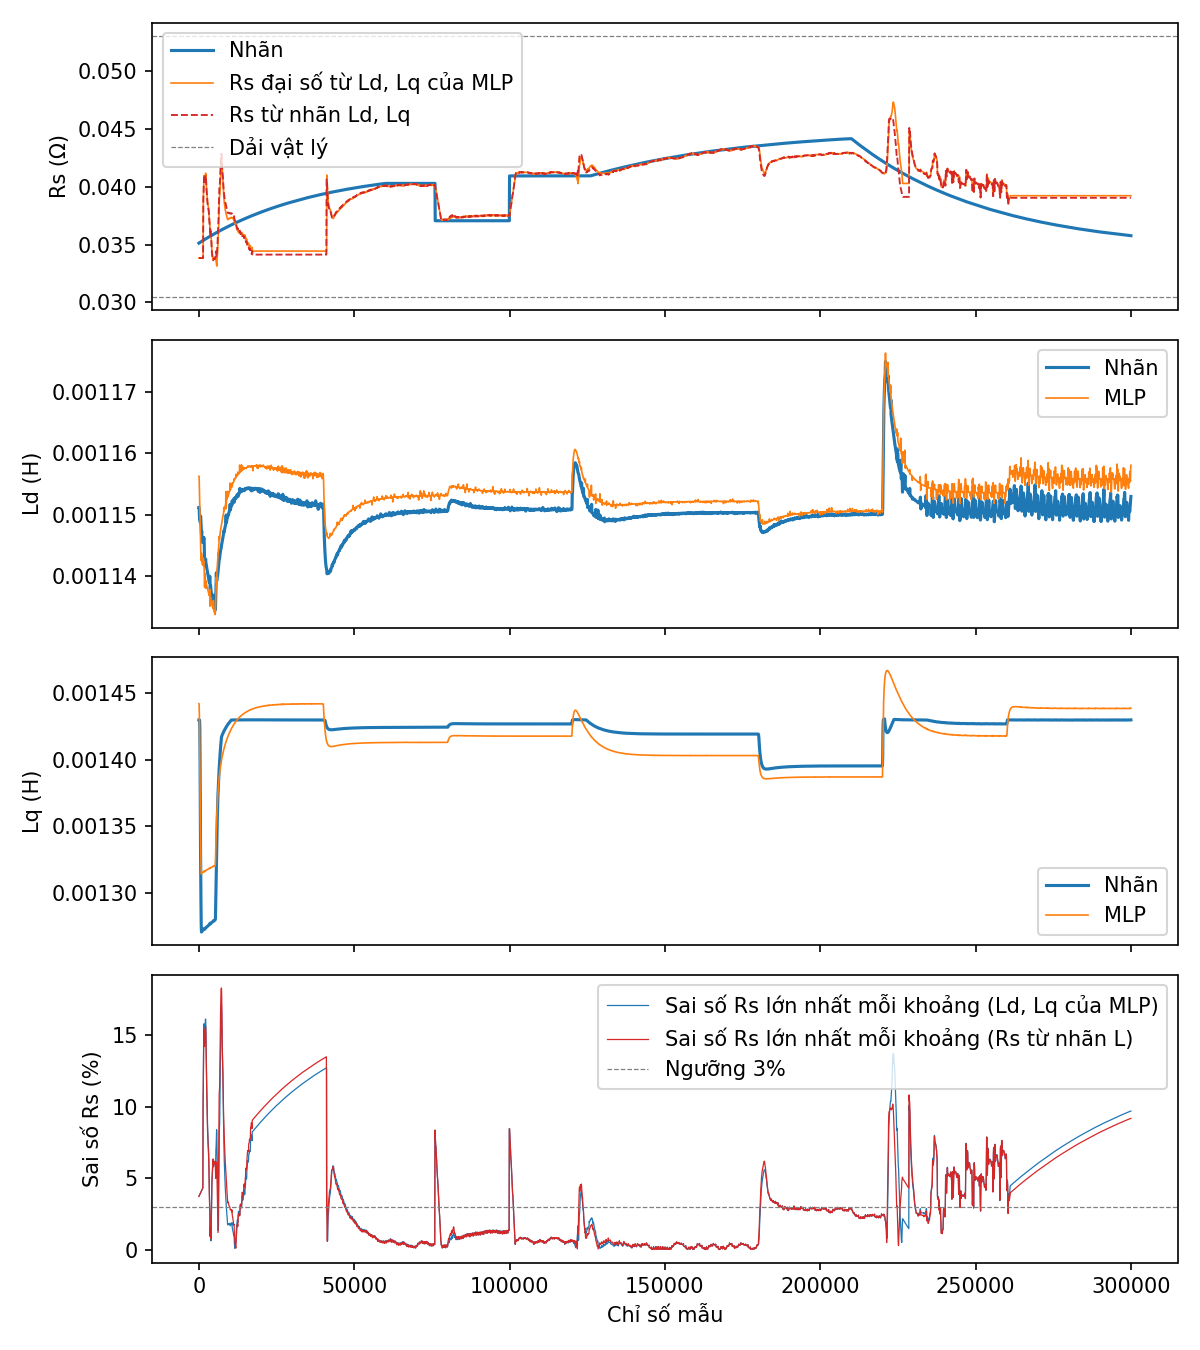

In [9]:
# Cell 9 - Lập bảng kết quả tổng hợp và so sánh với Rs từ nhãn Ld, Lq
vs = cfg['evaluation']['verdict_stat']  # Thống kê kết luận
rows = []  # Danh sách hàng kết quả
for r in res['parameters']:  # Toàn bộ mẫu
    rows.append({'scope': 'toàn bộ', 'param': r['param'], 'condition': r['condition'], 'limit_pct': r['limit_pct'], 'stat': vs, 'value_pct': r[vs], 'pass': r['pass']})  # Ghi một hàng
for r in res['parameters_excl_startup']:  # Sau khi loại đoạn khởi động
    rows.append({'scope': 'sau khởi động', 'param': r['param'], 'condition': r['condition'], 'limit_pct': r['limit_pct'], 'stat': vs, 'value_pct': r[vs], 'pass': r['pass']})  # Ghi một hàng
for r in res['rs_oracle']['parameters_excl_startup']:  # Đối chứng Rs từ nhãn Ld, Lq
    rows.append({'scope': 'Rs từ nhãn Ld, Lq (sau khởi động)', 'param': r['param'], 'condition': r['condition'], 'limit_pct': r['limit_pct'], 'stat': vs, 'value_pct': r[vs], 'pass': r['pass']})  # Ghi một hàng
rows.append({'scope': 'toàn bộ', 'param': 'id_iq_RMSE', 'condition': 'toàn dải', 'limit_pct': cfg['evaluation']['rmse_limit_pct'], 'stat': 'rmse', 'value_pct': max(res['current_rmse']['id_pct'], res['current_rmse']['iq_pct']), 'pass': res['current_rmse']['pass']})  # Hàng RMSE dòng điện
comp = pd.DataFrame(rows)  # Bảng kết quả
comp.to_csv(os.path.join(PATHS['results'], 'results_summary.csv'), index=False)  # Lưu vào Drive
display(comp)  # Hiển thị bảng
ro_ = res['rs_oracle']  # Kết quả Rs từ nhãn Ld, Lq
mx = {x['condition']: x for x in res['parameters_excl_startup'] if x['param'] == 'Rs'}  # Rs của MLP sau khởi động
orx = {x['condition']: x for x in ro_['parameters_excl_startup']}  # Đối chứng sau khởi động
cmp_o = pd.DataFrame([{'condition': c_, 'n': mx[c_]['n'], 'MLP_mean': mx[c_]['mean'], 'nhanL_mean': orx[c_]['mean'], 'MLP_p95': mx[c_]['p95'], 'nhanL_p95': orx[c_]['p95'], 'MLP_max': mx[c_]['max'], 'nhanL_max': orx[c_]['max']} for c_ in ('steady', 'transient')])  # Bảng so sánh
print('So sánh sai số Rs (%) sau khởi động: Ld, Lq của MLP với Rs từ nhãn Ld, Lq:'); display(cmp_o.round(3))  # Hiển thị so sánh
seg_o = pd.DataFrame([{'seg': a_['seg'], 'MLP_mean': a_['mean'], 'nhanL_mean': b_['mean'], 'MLP_max': a_['max'], 'nhanL_max': b_['max']} for a_, b_ in zip(res['rs_segments'], ro_['segments'])])  # Sai số theo mười đoạn
print('Sai số Rs xác lập theo mười đoạn liên tiếp (%):'); display(seg_o.round(3))  # Hiển thị theo đoạn
print('Sai lệch có dấu (%): MLP', round(res['rs_signed_bias_pct'], 3), '| nhãn L', round(ro_['signed_bias_pct'], 3), '| tỷ lệ giữ giá trị: MLP', round(res['rs_estimator']['frac_held'], 4), '| nhãn L', round(ro_['frac_held'], 4), '| tỷ lệ mẫu MLP tốt hơn nhãn L:', round(ro_['frac_mlp_better_than_oracle'], 3))  # Tóm tắt
m_ml, m_or = mx['steady']['mean'], orx['steady']['mean']  # Sai số trung bình Rs xác lập
if m_or > 1.2 * m_ml:  # Đối chứng sai nhiều hơn MLP
    print('Đọc kết quả: Rs từ nhãn Ld, Lq SAI NHIỀU HƠN Rs từ Ld, Lq của MLP. Ld, Lq của MLP không chỉ gần nhãn mà còn bù sai lệch của mô hình (Ψm hằng, bão hòa chéo); Ld, Lq báo cáo là tham số hiệu dụng. Cần đối chiếu sai số Ld, Lq với dung sai khi PRD chốt.')  # Kết luận tự động
elif m_or < m_ml / 1.2:  # Đối chứng tốt hơn MLP
    print('Đọc kết quả: Rs từ nhãn Ld, Lq TỐT HƠN Rs từ MLP. Sai số Ld, Lq của MLP là nút thắt của Rs; hướng cải tiến: huấn luyện lại hoặc làm trơn Ld, Lq.')  # Kết luận tự động
else:  # Tương đương
    print('Đọc kết quả: hai mức tương đương. Giới hạn nằm ở bộ ước lượng hoặc dữ liệu (đạo hàm dòng, gợn PWM, độ kích thích iq, mô hình Ψm), không phải ở Ld, Lq của MLP.')  # Kết luận tự động
from IPython.display import Image  # Hiển thị ảnh
display(Image(os.path.join(PATHS['results'], 'tracking_mlp_rs_test.png')))  # Đồ thị bám nhãn (đường đứt đỏ là Rs từ nhãn Ld, Lq; khung dưới là sai số Rs của cả hai)

## Cell 10 – Bước 4: đẩy lên GitHub

In [10]:
# Cell cuối - Bước 4: đẩy tệp đã kiểm thử đạt lên GitHub
assert TESTS_OK, 'Chưa đạt toàn bộ kiểm thử, không được đẩy mã'  # Chặn đẩy mã khi kiểm thử chưa đạt
push_files(['src/evaluation/metrics.py', 'src/evaluation/test.py'], 'Cập nhật metrics.py và test.py: đánh giá MLP Ld, Lq và Rs đại số')  # Đẩy các tệp lên nhánh main

To https://github.com/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02.git
   c606160..ad5d9e3  HEAD -> main

